# Assignment 3: Data Integration & Data Preparation

Below are all imported libraries used in this notebook.

In [1]:
#task 1
# !pip install -r requirements.txt
import re
import sys
import time
import random

import numpy as np
import pandas as pd
import Bio
import rapidfuzz
from Bio import Align
from rapidfuzz.distance import Levenshtein, Jaro

# task 2
import sqlite3
import pandas as pd

# task 3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

## Task 1: Record Matching (DBLP-ACM)

In this task we compare every record of `ACM.csv` with every record of `DBLP2.csv` and try to find the pairs that
describe the same paper. That is 2,294 × 2,616 = 6,001,104 comparisons. For every pair we compute four similarity
scores (title, authors, venue, year), combine them with weights, and call the pair a duplicate if the combined score is
above 0.7. At the end we check our pairs against `DBLP-ACM_perfectMapping.csv` and compute the precision.

**Setup.** Python 3.13.0, library versions are in `requirements.txt`. The three CSV files from the
[DBLP-ACM dataset](https://dbs.uni-leipzig.de/research/projects/benchmark-datasets-for-entity-resolution) need to be in the same folder as this notebook.

## Loading the data

`DBLP2.csv` is not UTF-8 (it has some Latin-1 characters in author names), so we have to pass `encoding='latin-1'`,
otherwise pandas crashes on it.

In [2]:
acm  = pd.read_csv(Path('Task1/ACM.csv'))
dblp = pd.read_csv(Path('Task1/DBLP2.csv'), encoding='latin-1')
gold = pd.read_csv(Path('Task1/DBLP-ACM_perfectMapping.csv'))

print('ACM records          :', len(acm))
print('DBLP2 records        :', len(dblp))
print('true matching pairs  :', len(gold))
print('pairs we must compare:', len(acm) * len(dblp))
acm.head(3)

ACM records          : 2294
DBLP2 records        : 2616
true matching pairs  : 2224
pairs we must compare: 6001104


,id,title,authors,venue,year
0,304586,The WASA2 object-oriented workflow management ...,"Gottfried Vossen, Mathias Weske",International Conference on Management of Data,1999
1,304587,A user-centered interface for querying distrib...,"Isabel F. Cruz, Kimberly M. James",International Conference on Management of Data,1999
2,304589,"World Wide Database-integrating the Web, CORBA...","Athman Bouguettaya, Boualem Benatallah, Lily H...",International Conference on Management of Data,1999


In [3]:
dblp.head(3)

,id,title,authors,venue,year
0,journals/sigmod/Mackay99,Semantic Integration of Environmental Models f...,D. Scott Mackay,SIGMOD Record,1999
1,conf/vldb/PoosalaI96,Estimation of Query-Result Distribution and it...,"Viswanath Poosala, Yannis E. Ioannidis",VLDB,1996
2,conf/vldb/PalpanasSCP02,Incremental Maintenance for Non-Distributive A...,"Themistoklis Palpanas, Richard Sidle, Hamid Pi...",VLDB,2002


In [4]:
# quick look at missing values: only 14 ACM records have no authors
print(acm.isna().sum().to_dict())
print(dblp.isna().sum().to_dict())

{'id': 0, 'title': 0, 'authors': 14, 'venue': 0, 'year': 0}
{'id': 0, 'title': 0, 'authors': 0, 'venue': 0, 'year': 0}


## Steps 1-3: cleaning the values

* **Step 1:** we don't use `id` (the pub_id) in any similarity. We only carry it along so that we know which records we matched.
* **Step 2:** everything to lowercase.
* **Step 3:** remove spaces at the start and end, and turn several spaces in a row into one space.

If a value is missing (the 14 empty author fields) we just use an empty string.

In [5]:
def clean(value):
    if pd.isna(value):
        return ''
    value = str(value).lower()                 # step 2: lowercase
    value = re.sub(r'\s+', ' ', value)         # step 3: many spaces -> one space
    return value.strip()                       # step 3: trim start and end

def prepare(df):
    # one tuple per record: (id, title, authors, venue, year)
    # the id is only kept for the evaluation (step 1)
    return list(zip(df['id'],
                    df['title'].map(clean),
                    df['authors'].map(clean),
                    df['venue'].map(clean),
                    df['year'].astype(int)))

A = prepare(acm)    # ACM records   (r_i)
D = prepare(dblp)   # DBLP2 records (r_j)
print(A[0])
print(D[0])

(304586, 'the wasa2 object-oriented workflow management system', 'gottfried vossen, mathias weske', 'international conference on management of data', 1999)
('journals/sigmod/Mackay99', 'semantic integration of environmental models for application to global information systems and decision-making', 'd. scott mackay', 'sigmod record', 1999)


## Steps 4-7: the four similarity measures

### Title: Levenshtein similarity (step 4)

The minimum edit distance (MED) is the smallest number of inserts, deletes and substitutions needed to turn one string
into the other. We first wrote it ourselves with the dynamic programming table from the lecture (same as the
`ldist` exercise in the week 6 lab). Then the similarity is

$$L_{sim}(S_1,S_2) = 1 - \frac{MED(S_1,S_2)}{\max(|S_1|,|S_2|)}$$

We use cost 1 for every operation (insert, delete and substitute). The lecture also shows a version where a substitution costs 2,
but with that version MED can become bigger than the longest string and the formula above would give negative similarities.
With cost 1 the MED is never larger than the longer string, so the score always stays between 0 and 1, which is what the
formula in the assignment expects.

In [6]:
def med(s, t, sub_cost=1):
    # dynamic programming table from the lecture, but we only keep the previous row to save memory
    prev = list(range(len(t) + 1))              # D(0, j) = j
    for i in range(1, len(s) + 1):
        cur = [i]                                # D(i, 0) = i
        for j in range(1, len(t) + 1):
            cost = 0 if s[i - 1] == t[j - 1] else sub_cost
            cur.append(min(prev[j] + 1,          # delete
                           cur[j - 1] + 1,       # insert
                           prev[j - 1] + cost))  # substitute (or match)
        prev = cur
    return prev[-1]

def lev_sim_own(s1, s2):
    if not s1 or not s2:
        return 0.0
    return 1 - med(s1, s2) / max(len(s1), len(s2))

# examples from the lecture slides
print(med('intention', 'execution'))              # 5
print(med('intention', 'execution', sub_cost=2))  # 8

5
8


### Authors: Jaro similarity (step 5)

Again we first wrote it ourselves following the lecture: two characters are *common* if they are equal and not more
than $\lfloor \max(|S_1|,|S_2|)/2 \rfloor - 1$ positions apart, $T$ is half the number of common characters that are in a
different order (rounded down, more on that below), and

$$Jaro(S_1,S_2) = \frac{1}{3}\left(\frac{C}{|S_1|} + \frac{C}{|S_2|} + \frac{C - T}{C}\right)$$

In [7]:
def jaro_own(s1, s2):
    if not s1 or not s2:
        return 0.0
    window = max(max(len(s1), len(s2)) // 2 - 1, 0)
    used1 = [False] * len(s1)
    used2 = [False] * len(s2)
    c = 0
    # find the common characters
    for i, ch in enumerate(s1):
        for j in range(max(0, i - window), min(len(s2), i + window + 1)):
            if not used2[j] and s2[j] == ch:
                used1[i] = used2[j] = True
                c += 1
                break
    if c == 0:
        return 0.0
    # count the common characters that are in a different order
    common1 = [ch for ch, u in zip(s1, used1) if u]
    common2 = [ch for ch, u in zip(s2, used2) if u]
    t = sum(a != b for a, b in zip(common1, common2)) // 2   # half, rounded down
    return (c / len(s1) + c / len(s2) + (c - t) / c) / 3

# examples from the lecture slides
print(round(jaro_own('deis', 'desi'), 4))    # 0.9167
print(round(jaro_own('arnab', 'aranb'), 4))  # 0.9333

0.9167
0.9333


One small detail we ran into: in our first version we computed $T$ as a normal division by 2. When we compared it with the
libraries (rapidfuzz, jellyfish, textdistance) we got slightly different numbers for about half of the author pairs. It turned out
all of these libraries round $T$ down (integer division), like the original Jaro-Winkler code does. When the number of
out-of-order characters is even, like in the lecture examples, both versions give the same result. We switched to `// 2`
so our function matches the standard implementations.

### Our own functions vs. a library

Our pure Python functions are correct but slow (we measure how slow further down). The `rapidfuzz` library has the
same two algorithms written in C++, so for the real run over 6 million pairs we use rapidfuzz. To be sure it computes exactly the same thing as our
own code, we compare both on 20,000 random record pairs.

In [8]:
def lev_sim(s1, s2):        # step 4, title
    if not s1 or not s2:
        return 0.0
    return 1 - Levenshtein.distance(s1, s2) / max(len(s1), len(s2))

def jaro_sim(s1, s2):       # step 5, authors
    if not s1 or not s2:
        return 0.0
    return Jaro.similarity(s1, s2)

random.seed(42)
sample = [(random.choice(A), random.choice(D)) for _ in range(20000)]
max_diff_lev  = max(abs(lev_sim(a[1], d[1]) - lev_sim_own(a[1], d[1])) for a, d in sample)
max_diff_jaro = max(abs(jaro_sim(a[2], d[2]) - jaro_own(a[2], d[2])) for a, d in sample)
print('largest difference, Levenshtein:', max_diff_lev)
print('largest difference, Jaro       :', max_diff_jaro)

largest difference, Levenshtein: 0.0
largest difference, Jaro       : 0.0


### Venue: affine-gap similarity (step 6)

The normal edit distance punishes short forms a lot: *"vldb"* vs *"very large data bases"* needs 17 inserts.
The affine-gap distance fixes this: opening a gap costs more, but making an already open gap longer is cheap. That fits
abbreviations well.

As the assignment suggests we use Biopython's `PairwiseAligner` with `open_gap_score = -1`, `extend_gap_score = -0.1` and
`mismatch_score = -2`. Biopython gives back an alignment **score** (higher is better), not a distance. We set `match_score = 0`,
so every score is 0 or negative, and the best score is exactly minus the cheapest affine-gap edit cost. So
$d_{aff} = -\text{score}$ and then

$$sim_{aff}(S_1,S_2) = \frac{1}{1 + \frac{d_{aff}(S_1,S_2)}{\max(|S_1|,|S_2|)}}$$

We use `mode = 'global'` because we want to align the whole venue names and not just a piece of them.

In [9]:
aligner = Align.PairwiseAligner()
aligner.mode = 'global'
aligner.match_score = 0
aligner.mismatch_score = -2
aligner.open_gap_score = -1
aligner.extend_gap_score = -0.1

def affine_sim(s1, s2):     # step 6, venue
    if not s1 or not s2:
        return 0.0
    d_aff = -aligner.score(s1, s2)          # score <= 0, so the distance is -score
    return 1 / (1 + d_aff / max(len(s1), len(s2)))

def year_sim(y1, y2):       # step 7, year: match = 1, mismatch = 0
    return 1.0 if y1 == y2 else 0.0

for v1, v2 in [('vldb', 'very large data bases'),
               ('sigmod record', 'acm sigmod record'),
               ('vldb', 'international conference on management of data')]:
    print(f'{v1!r:18} vs {v2!r:50} -> {affine_sim(v1, v2):.3f}')

'vldb'             vs 'very large data bases'                            -> 0.837
'sigmod record'    vs 'acm sigmod record'                                -> 0.929
'vldb'             vs 'international conference on management of data'   -> 0.871


The last example shows a problem with the venue score: *"vldb"* vs *"international conference on management of data"*
is the **wrong** venue but still gets 0.87, because the short string can be "spread out" over the long one with cheap gaps.
So the venue score is not very useful for telling papers apart. We keep that in mind when we choose the weights.

## Step 8: choosing the weights

$$sim_{rec}(r_i, r_j) = \omega_1 s_t + \omega_2 s_a + \omega_3 s_c + \omega_4 s_y$$

We picked **ω1 = 0.5 (title), ω2 = 0.2 (authors), ω3 = 0.1 (venue), ω4 = 0.2 (year)**. All are positive and they add up to 1.

Why these values:
* **Title gets the most weight.** Two different papers almost never have almost the same title, so it is the strongest signal.
* **Authors 0.2.** Useful, but Jaro on a whole author list already gives around 0.5-0.6 for two lists that have nothing to do
  with each other, and the two sources sometimes write names differently.
* **Venue only 0.1.** There are only 5 venues on each side, the names are written totally differently in the two files, and as
  we saw above even the wrong venue gets a high score.
* **Year 0.2.** A real match needs the same year, but thousands of different papers also share a year, so it should
  help but not decide on its own.

(The numbers about authors and venue in this list are computed after the full run, in the section *Checking the numbers we used in the text*.)

A nice side effect: with these weights a pair can only get above 0.7 if the title similarity is above 0.4,
because the other three weights add up to 0.5 at most.

In [10]:
W = (0.5, 0.2, 0.1, 0.2)    # w1 title, w2 authors, w3 venue, w4 year
THRESHOLD = 0.7
assert all(w > 0 for w in W) and abs(sum(W) - 1) < 1e-9

## Step 9 (and the timing for step 11): comparing all pairs

Here we just loop over all ACM records and, for each one, over all DBLP2 records. If the combined score is above 0.7,
we store the two ids in the list `duplicates`.

We also save the four separate scores of every pair in a numpy array `S`. That's not needed for the method itself, but
it lets us try other weights afterwards without running the whole loop again.

In [11]:
n_a, n_d = len(A), len(D)
S = np.empty((n_a * n_d, 4), dtype=np.float32)   # the 4 scores per pair, only for the extra analysis
duplicates = []                                    # (idACM, idDBLP) pairs with sim_rec > 0.7
w1, w2, w3, w4 = W

start = time.perf_counter()
k = 0
for (id_a, title_a, auth_a, venue_a, year_a) in A:
    for (id_d, title_d, auth_d, venue_d, year_d) in D:
        s_t = lev_sim(title_a, title_d)
        s_a = jaro_sim(auth_a, auth_d)
        s_c = affine_sim(venue_a, venue_d)
        s_y = year_sim(year_a, year_d)
        S[k] = (s_t, s_a, s_c, s_y)
        k += 1
        if w1 * s_t + w2 * s_a + w3 * s_c + w4 * s_y > THRESHOLD:   # step 9
            duplicates.append((id_a, id_d))
elapsed = time.perf_counter() - start

print(f'pairs compared     : {k:,}')
print(f'duplicates reported: {len(duplicates):,}')
print(f'running time       : {elapsed:.1f} s ({elapsed / 60:.1f} min)')
print(f'time per pair      : {elapsed / k * 1e6:.1f} microseconds')

pairs compared     : 6,001,104
duplicates reported: 2,560
running time       : 29.5 s (0.5 min)
time per pair      : 4.9 microseconds


## Step 10: precision

Precision = (number of reported pairs that are also in the perfect mapping) / (number of reported pairs).
We also print the recall, just to see how many of the real matches we found, even though the assignment only asks for precision.

In [12]:
gold_pairs = set(zip(gold['idACM'], gold['idDBLP']))
reported = set(duplicates)
correct = len(reported & gold_pairs)

precision = correct / len(reported)
recall = correct / len(gold_pairs)

print(f'reported pairs : {len(reported):,}')
print(f'correct pairs  : {correct:,}')
print(f'PRECISION      : {precision:.4f}')
print(f'recall (extra) : {recall:.4f}')

reported pairs : 2,560
correct pairs  : 2,201
PRECISION      : 0.8598
recall (extra) : 0.9897


Let's look at some pairs we reported that are **not** in the perfect mapping (false positives):

In [13]:
acm_by_id = acm.set_index('id')
dblp_by_id = dblp.set_index('id')
rows = []
for id_a, id_d in sorted(reported - gold_pairs)[:10]:
    rows.append({'ACM title': acm_by_id.loc[id_a, 'title'],
                 'DBLP title': dblp_by_id.loc[id_d, 'title'],
                 'ACM year': acm_by_id.loc[id_a, 'year'],
                 'DBLP year': dblp_by_id.loc[id_d, 'year']})
pd.set_option('display.max_colwidth', 80)
pd.DataFrame(rows)

,ACM title,DBLP title,ACM year,DBLP year
0,A taxonomy for secure object-oriented databases,Index Configuration in Object-Oriented Databases,1994,1994
1,Observations on the ODMG-93 proposal for an object-oriented database language,UniSQL/X Unified Relational and Object-Oriented Database System,1994,1994
2,Databases for GIS,Databases for Networks,1994,1994
3,Metadata for multimedia documents,Metadata for Mixed-Media Access,1994,1994
4,Metadata for mixed-media access,Metadata for Multimedia Documents,1994,1994
5,Sleepers and workaholics: caching strategies in mobile environments,Sleepers and Workaholics: Caching Strategies in Mobile Environments,1994,1995
6,Estimating page fetches for index scans with finite LRU buffers,Estimating Page Fetches for Index Scans with Finite LRU Buffers,1994,1995
7,QuickStore: a high performance mapped object store,QuickStore: A High Performance Mapped Object Store,1994,1995
8,XSB as an efficient deductive database engine,XSB as a Deductive Database,1994,1994
9,The ORES temporal database management system,Open Object Database Management Systems,1994,1994


Most mistakes are short titles that look a lot alike and are from the same year, like *"Metadata for multimedia documents"*
vs *"Metadata for mixed-media access"*. The title is already fairly similar, and then the year (+0.2) and the venue
(almost always around 0.85) push the total over 0.7. A few pairs have the same title but a different year. They are probably
different versions of the same paper (for example a conference and a journal version), and the perfect mapping does not count those as the same publication.

### Checking the numbers we used in the text

In step 8 we said that Jaro gives around 0.5-0.6 for author lists that have nothing to do with each other, and that the venue
score is high even for wrong venues. Since we stored all scores in `S`, we can check this here. We split the pairs into the 2,224
true matches and all other (non-matching) pairs and look at the author and venue scores of both groups.

In [14]:
# position of every true match in S (row = i * n_d + j)
pos_a = {r[0]: i for i, r in enumerate(A)}
pos_d = {r[0]: j for j, r in enumerate(D)}
is_match = np.zeros(len(S), dtype=bool)
for id_a, id_d in gold_pairs:
    is_match[pos_a[id_a] * n_d + pos_d[id_d]] = True

rows = []
for name, col in [('authors (Jaro)', 1), ('venue (affine gap)', 2)]:
    for group, mask in [('true matches', is_match), ('non-matching pairs', ~is_match)]:
        v = S[mask, col]
        rows.append({'score': name, 'pairs': group, 'count': len(v),
                     'mean': v.mean(), 'median': np.median(v),
                     '25%': np.percentile(v, 25), '75%': np.percentile(v, 75),
                     'share > 0.8': (v > 0.8).mean()})
pd.DataFrame(rows).round(3)

,score,pairs,count,mean,median,25%,75%,share > 0.8
0,authors (Jaro),true matches,2224,0.844,0.831,0.757,1.000,0.609
1,authors (Jaro),non-matching pairs,5998880,0.539,0.550,0.503,0.592,0.000
2,venue (affine gap),true matches,2224,0.875,0.871,0.837,0.885,1.000
3,venue (affine gap),non-matching pairs,5998880,0.845,0.853,0.808,0.871,0.830


This confirms what we wrote in step 8. For non-matching pairs the Jaro score of the authors has a median of 0.55, and half of
them are between about 0.50 and 0.59, so even unrelated author lists get around 0.5-0.6. The true matches only have a mean of 0.84
(not close to 1), because the two sources write names a bit differently. For the venue, the non-matching pairs have a median of
0.85 and 83% of them score above 0.8, almost the same as the true matches (0.87). So the venue score hardly separates the two groups,
which is why it got the lowest weight.

In [15]:
# other small facts we use in the text
print('distinct venues in ACM  :', acm['venue'].nunique())
print('distinct venues in DBLP2:', dblp['venue'].nunique())
print('average title length (characters):', round(np.mean([len(r[1]) for r in A + D]), 1))
print(f'share of true matches among all pairs: {len(gold_pairs) / (n_a * n_d):.4%}')
print('edit distance vldb vs very large data bases:', med('vldb', 'very large data bases'))

distinct venues in ACM  : 5
distinct venues in DBLP2: 5
average title length (characters): 56.6
share of true matches among all pairs: 0.0371%
edit distance vldb vs very large data bases: 17


### Extra: what happens with other weights?

This is not asked in the assignment, but we were curious how much the weights matter. Because we stored the four scores,
we can recompute the precision for other weights instantly.

In [16]:
ids_a = np.repeat(np.array([r[0] for r in A], dtype=object), n_d)
ids_d = np.tile(np.array([r[0] for r in D], dtype=object), n_a)

def evaluate(scores, w, thr=THRESHOLD):
    total = scores @ np.asarray(w, dtype=np.float32)
    idx = np.nonzero(total > thr)[0]
    rep = set(zip(ids_a[idx], ids_d[idx]))
    ok = len(rep & gold_pairs)
    return len(rep), ok, ok / len(rep), ok / len(gold_pairs)

weights_to_try = [(0.25, 0.25, 0.25, 0.25), (0.4, 0.3, 0.1, 0.2), (0.5, 0.2, 0.1, 0.2),
                  (0.5, 0.3, 0.1, 0.1), (0.6, 0.2, 0.1, 0.1), (0.7, 0.1, 0.1, 0.1)]
cols = ['w1 title', 'w2 authors', 'w3 venue', 'w4 year', 'reported', 'correct', 'precision', 'recall']
pd.DataFrame([list(w) + list(evaluate(S, w)) for w in weights_to_try], columns=cols).round(4)

,w1 title,w2 authors,w3 venue,w4 year,reported,correct,precision,recall
0,0.25,0.25,0.25,0.25,13351,2220,0.1663,0.9982
1,0.40,0.30,0.10,0.20,2494,2204,0.8837,0.9910
2,0.50,0.20,0.10,0.20,2560,2201,0.8598,0.9897
3,0.50,0.30,0.10,0.10,2582,2193,0.8493,0.9861
4,0.60,0.20,0.10,0.10,2575,2188,0.8497,0.9838
5,0.70,0.10,0.10,0.10,2564,2181,0.8506,0.9807


Equal weights are really bad (precision 0.17), because venue and year are high for a huge number of wrong pairs. As soon as the
title gets most of the weight, the precision goes to around 0.85-0.88. Giving authors a bit more weight (0.4/0.3/0.1/0.2) is
slightly better than our choice, but we kept our original weights because we chose them before looking at the results.

And for completeness, the Levenshtein version with substitution cost 2 from the lecture (only the title score changes):

In [17]:
titles_a = [r[1] for r in A]
titles_d = [r[1] for r in D]
S2 = S.copy()
S2[:, 0] = [1 - Levenshtein.distance(ta, td, weights=(1, 1, 2)) / max(len(ta), len(td))
            for ta in titles_a for td in titles_d]
print('lowest title score with substitution cost 2:', S2[:, 0].min())
rep, ok, p, r = evaluate(S2, W)
print(f'reported {rep}, correct {ok}, precision {p:.4f}, recall {r:.4f}')

lowest title score with substitution cost 2: -0.8333333
reported 2487, correct 2199, precision 0.8842, recall 0.9888


With substitution cost 2 some title scores become negative (down to -0.83), so it is not really a similarity "between 0 and 1"
anymore. The precision happens to come out a bit higher (0.88), because titles that only look a bit alike get pushed down harder.
We still stick to cost 1 for the main answer, because that is the version where the assignment's formula stays between 0 and 1.

## Step 11: running time and how to make it faster

### How long did it take?

With rapidfuzz (C++) and Biopython (C) the full run above took **under a minute** on our machine. That is only because the
heavy string code is not in Python. If we use our own pure Python functions from above (the way we did it in the lab),
it is much slower. We can't wait for that on all 6 million pairs, so we time 5,000 random pairs and scale up:

In [18]:
random.seed(1)
test_pairs = [(random.choice(A), random.choice(D)) for _ in range(5000)]

t0 = time.perf_counter()
for a, d in test_pairs:
    w1 * lev_sim_own(a[1], d[1]) + w2 * jaro_own(a[2], d[2]) + w3 * affine_sim(a[3], d[3]) + w4 * year_sim(a[4], d[4])
per_pair = (time.perf_counter() - t0) / len(test_pairs)

print(f'pure Python: {per_pair * 1e6:.0f} microseconds per pair')
print(f'estimated time for all {n_a * n_d:,} pairs: {per_pair * n_a * n_d / 60:.0f} minutes')

pure Python: 361 microseconds per pair
estimated time for all 6,001,104 pairs: 36 minutes


So with "normal" Python code the method needs a long time, which is what the assignment means.

### Why is it slow?

1. **Every record is compared with every other record.** The number of comparisons is |ACM| × |DBLP2|, so it grows
   quadratically. If both tables were 10 times bigger, it would take 100 times longer.
2. **Each comparison is itself expensive.** Levenshtein and the affine gap both fill a dynamic programming table of size
   |S1| × |S2|, and Jaro also has a loop inside a loop. Titles are around 60 characters, so that's a few thousand steps per pair just for the title.
3. **Almost all of that work is useless.** Only 2,224 of the 6 million pairs (0.04%) are real matches. Nearly all the time goes into
   confirming that two obviously different papers are different.

### What could we do about it? (not implemented)

We don't implement these ideas, but for the first one (blocking on the year) we quickly check two numbers that we use below:
do all true matches have the same year in both files, and how many pairs would be left if we only compared records from the same year?

In [19]:
year_a = dict(zip(acm['id'], acm['year']))
year_d = dict(zip(dblp['id'], dblp['year']))
same_year = sum(year_a[ia] == year_d[idd] for ia, idd in gold_pairs)
print(f'true matches with the same year: {same_year} of {len(gold_pairs)}')

# pairs left when we only compare records from the same year
pairs_per_year = acm.groupby('year').size() * dblp.groupby('year').size()
print(pd.DataFrame({'ACM': acm.groupby('year').size(), 'DBLP2': dblp.groupby('year').size(),
                    'pairs': pairs_per_year}))
print(f'pairs with year blocking: {pairs_per_year.sum():,} instead of {n_a * n_d:,} '
      f'({n_a * n_d / pairs_per_year.sum():.1f} times fewer)')

true matches with the same year: 2224 of 2224
      ACM  DBLP2  pairs
year                   
1994  217    231  50127
1995  239    249  59511
1996  218    222  48396
1997  203    209  42427
1998  239    249  59511
1999  220    234  51480
2000  249    264  65736
2001  282    288  81216
2002  221    324  71604
2003  206    346  71276
pairs with year blocking: 601,284 instead of 6,001,104 (10.0 times fewer)


Now the ideas themselves:

1. **Blocking.** Only compare records that share some key and skip the rest. In this dataset all 2,224 true matches have
   the same year in both files, so if we only compare papers from the same year we go from 6,001,104 to 601,284 pairs (10 times less)
   and we don't lose a single true match. We could make the blocks even smaller with year + venue (after mapping
   "vldb" and "very large data bases" to the same group), or with the first word of the title. The risk is that a typo in the
   blocking key makes us miss a match, so it is safer to block on a few different keys and take the union of the candidate pairs.
2. **Hashing / LSH to get candidate pairs** (lecture on Heterogeneous Data Analysis). Turn each title into shingles, compute MinHash
   signatures and use Locality-Sensitive Hashing so that similar titles land in the same bucket. Then we only compare pairs that share a bucket.
   This goes from O(N²) comparisons to roughly O(N).
3. **An index on the title words** (lecture on Hashing and Indexing). Build an inverted index from words to records and only compare
   records that share at least one rare word in the title.
4. **Sorted neighbourhood.** Sort both tables by the cleaned title and only compare each record with the next few records
   in the sorted list (a sliding window).
5. **Stop early.** As shown in step 8, a pair can never get above 0.7 if its title similarity is 0.4 or lower. So first compute the
   year and the title, and only compute authors and venue for the pairs that still have a chance.
   There are also cheap checks before Levenshtein: if the two title lengths are very different, the similarity can't be high.
6. **Don't compute the same thing twice.** There are only 5 different venues in each file, so only 25 venue pairs exist. We could
   compute those 25 affine-gap scores once and look them up, instead of running the aligner 6 million times.
7. **Faster code and more cores.** Use C/C++ libraries (like rapidfuzz, which we already did) or Numba, and split the ACM table
   over several CPU cores. This helps a lot, but the number of comparisons stays the same, so it works best together with blocking.

In our opinion, blocking on the year plus caching the 25 venue scores plus stopping early on the title would already make
the method many times faster without losing any real matches.

## Task 2: Data Integration

We use `sqlite3` for the databases and pandas only to print the tables nicely. `show_table()` is a small helper that prints a whole table.

In [20]:
def show_table(con, table):
    print(table)
    display(pd.read_sql_query(f"SELECT * FROM {table}", con))

## Step 1: Source A

Source A has a `club` table (10 clubs) and a `player` table (12 players). Players point to their club through `club_id`. Names are stored in one column as first name + last name, dates are in ISO format and heights are in centimetres.

`sqlite3.connect()` creates the file if it isn't there yet. SQLite only enforces foreign keys when you switch them on for the connection, so every connection that writes data in this notebook starts with `PRAGMA foreign_keys = ON`. The rows are sample data we typed in for this demo.

In [21]:
con = sqlite3.connect("source_a_league.db")
con.execute("PRAGMA foreign_keys = ON")

con.executescript("""
DROP TABLE IF EXISTS player;
DROP TABLE IF EXISTS club;

CREATE TABLE club (
    club_id   INTEGER PRIMARY KEY,
    club_name TEXT NOT NULL,
    city      TEXT
);

CREATE TABLE player (
    player_id  INTEGER PRIMARY KEY,
    full_name  TEXT NOT NULL,   -- e.g. 'Luuk de Jong'
    birth_date TEXT,            -- yyyy-mm-dd
    height_cm  INTEGER,
    club_id    INTEGER REFERENCES club(club_id)
);

INSERT INTO club VALUES
 (1,  'Ajax',            'Amsterdam'),
 (2,  'PSV',             'Eindhoven'),
 (3,  'FC Utrecht',      'Utrecht'),
 (4,  'Feyenoord',       'Rotterdam'),
 (5,  'AZ',              'Alkmaar'),
 (6,  'FC Twente',       'Enschede'),
 (7,  'SC Heerenveen',   'Heerenveen'),
 (8,  'Sparta',          'Rotterdam'),
 (9,  'NEC',             'Nijmegen'),
 (10, 'Go Ahead Eagles', 'Deventer');

INSERT INTO player VALUES
 (101, 'Jordan Henderson',   '1990-06-17', 182, 1),
 (102, 'Luuk de Jong',       '1990-08-27', 188, 2),
 (103, 'Mike van der Hoorn', '1992-10-15', 191, 3),
 (104, 'Kenneth Taylor',     '2002-05-16', 182, 1),
 (105, 'Quinten Timber',     '2001-06-17', 177, 4),
 (106, 'Sem Steijn',         '2001-11-03', 177, 6),
 (107, 'Troy Parrott',       '2002-02-04', 185, 5),
 (108, 'Joshua Kitolano',    '2001-07-03', 182, 8),
 (109, 'Kodai Sano',         '2003-09-26', 176, 9),
 (110, 'Mats Deijl',         '1997-06-15', 181, 10),
 (111, 'Jacob Trenskow',     '2000-05-27', 183, 7),
 (112, 'Brian Brobbey',      '2002-02-01', 181, 1);
""")
con.commit()

show_table(con, "club")
show_table(con, "player")
con.close()

club


,club_id,club_name,city
0,1,Ajax,Amsterdam
1,2,PSV,Eindhoven
2,3,FC Utrecht,Utrecht
3,4,Feyenoord,Rotterdam
4,5,AZ,Alkmaar
5,6,FC Twente,Enschede
6,7,SC Heerenveen,Heerenveen
7,8,Sparta,Rotterdam
8,9,NEC,Nijmegen
9,10,Go Ahead Eagles,Deventer


player


,player_id,full_name,birth_date,height_cm,club_id
0,101,Jordan Henderson,1990-06-17,182,1
1,102,Luuk de Jong,1990-08-27,188,2
2,103,Mike van der Hoorn,1992-10-15,191,3
3,104,Kenneth Taylor,2002-05-16,182,1
4,105,Quinten Timber,2001-06-17,177,4
5,106,Sem Steijn,2001-11-03,177,6
6,107,Troy Parrott,2002-02-04,185,5
7,108,Joshua Kitolano,2001-07-03,182,8
8,109,Kodai Sano,2003-09-26,176,9
9,110,Mats Deijl,1997-06-15,181,10


## Step 2: Source B

Source B stores the same kind of information in its own way. The tables are called `team` and `squad_member`, clubs are identified by a three letter code, team names are the long official ones, names are written as "Last, First", dates use day/month/year and heights are in metres. It also has a `country` column where A has `city`.

The overlap is on purpose. Some clubs only exist in A (Sparta, NEC), some only in B (Fortuna Sittard, PEC Zwolle), and Henderson, de Jong, Taylor and Timber are in both. Without this overlap there wouldn't be much to integrate.

In [22]:
con = sqlite3.connect("source_b_transfers.db")
con.execute("PRAGMA foreign_keys = ON")

con.executescript("""
DROP TABLE IF EXISTS squad_member;
DROP TABLE IF EXISTS team;

CREATE TABLE team (
    team_code TEXT PRIMARY KEY,   -- 'AJX', 'PSV', ...
    team_name TEXT NOT NULL,
    country   TEXT
);

CREATE TABLE squad_member (
    member_key TEXT PRIMARY KEY,  -- 'TM-2001', ...
    name       TEXT NOT NULL,     -- 'Last, First'
    dob        TEXT,              -- dd/mm/yyyy
    height_m   REAL,              -- in metres!
    team_code  TEXT REFERENCES team(team_code)
);

INSERT INTO team VALUES
 ('AJX', 'AFC Ajax',            'Netherlands'),
 ('PSV', 'PSV Eindhoven',       'Netherlands'),
 ('AZ',  'AZ Alkmaar',          'Netherlands'),
 ('FEY', 'Feyenoord Rotterdam', 'Netherlands'),
 ('TWE', 'FC Twente Enschede',  'Netherlands'),
 ('UTR', 'FC Utrecht',          'Netherlands'),
 ('HEE', 'sc Heerenveen',       'Netherlands'),
 ('GAE', 'Go Ahead Eagles',     'Netherlands'),
 ('FOR', 'Fortuna Sittard',     'Netherlands'),
 ('PEC', 'PEC Zwolle',          'Netherlands');

INSERT INTO squad_member VALUES
 ('TM-2001', 'Henderson, Jordan',    '17/06/1990', 1.82, 'AJX'),
 ('TM-2002', 'de Jong, Luuk',        '27/08/1990', 1.88, 'PSV'),
 ('TM-2003', 'Veerman, Joey',        '19/11/1998', 1.83, 'PSV'),
 ('TM-2004', 'de Wit, Dani',         '28/01/1998', 1.80, 'AZ'),
 ('TM-2005', 'Taylor, Kenneth',      '16/05/2002', 1.82, 'AJX'),
 ('TM-2006', 'Timber, Quinten',      '17/06/2001', 1.77, 'FEY'),
 ('TM-2007', 'Saibari, Ismael',      '28/01/2001', 1.83, 'PSV'),
 ('TM-2008', 'Godts, Mika',          '07/05/2005', 1.74, 'AJX'),
 ('TM-2009', 'Stengs, Calvin',       '18/12/1998', 1.80, 'FEY'),
 ('TM-2010', 'Vlap, Michel',         '02/06/1997', 1.84, 'TWE'),
 ('TM-2011', 'Sierhuis, Kaj',        '27/04/1998', 1.87, 'FOR'),
 ('TM-2012', 'van den Belt, Thomas', '17/06/2001', 1.81, 'PEC');
""")
con.commit()

show_table(con, "team")
show_table(con, "squad_member")
con.close()

team


,team_code,team_name,country
0,AJX,AFC Ajax,Netherlands
1,PSV,PSV Eindhoven,Netherlands
2,AZ,AZ Alkmaar,Netherlands
3,FEY,Feyenoord Rotterdam,Netherlands
4,TWE,FC Twente Enschede,Netherlands
5,UTR,FC Utrecht,Netherlands
6,HEE,sc Heerenveen,Netherlands
7,GAE,Go Ahead Eagles,Netherlands
8,FOR,Fortuna Sittard,Netherlands
9,PEC,PEC Zwolle,Netherlands


squad_member


,member_key,name,dob,height_m,team_code
0,TM-2001,"Henderson, Jordan",17/06/1990,1.82,AJX
1,TM-2002,"de Jong, Luuk",27/08/1990,1.88,PSV
2,TM-2003,"Veerman, Joey",19/11/1998,1.83,PSV
3,TM-2004,"de Wit, Dani",28/01/1998,1.80,AZ
4,TM-2005,"Taylor, Kenneth",16/05/2002,1.82,AJX
5,TM-2006,"Timber, Quinten",17/06/2001,1.77,FEY
6,TM-2007,"Saibari, Ismael",28/01/2001,1.83,PSV
7,TM-2008,"Godts, Mika",07/05/2005,1.74,AJX
8,TM-2009,"Stengs, Calvin",18/12/1998,1.80,FEY
9,TM-2010,"Vlap, Michel",02/06/1997,1.84,TWE


## Step 3: Designing the warehouse

Before copying anything we had to agree on one format for the warehouse. We went with short club names, first and last name in separate columns, dates as `YYYY-MM-DD` and heights in whole centimetres. The warehouse also gets its own keys (`club_key`, `player_key`), so it doesn't depend on the ids of either source.

The integrated schema has four tables:

- `club` has one row per club, with the city from A and the country from B.
- `club_map` remembers which source id belongs to which warehouse club, so `('A', '1')` and `('B', 'AJX')` both point to Ajax.
- `player` has one row per player.
- `player_source` keeps track of where every player came from (lineage).

On top of that there are two audit tables. `rejected` lists every source row that could not be loaded, with the reason, so nothing disappears without a trace. `conflict_log` lists the cases where A and B say something different about the same player, and what we did about it.

**How we decide two rows are the same player.** We treat first name + last name + birth date as the matching key, enforced by `UNIQUE (first_name, last_name, birth_date)`. That is an assumption that works for this small made-up dataset; it is not a real identifier. Two different people could share all three values, and a typo in one source would turn one person into two rows. Step 7 shows how we at least flag that second case.

Every warehouse table is defined by explicit queries over the sources (step 5). That is the same idea as a global-as-view (GAV) mapping, where the global schema is written in terms of the sources. In our warehouse the result of those queries is stored, while a virtual GAV system would unfold the same definitions into subqueries every time a user asks something.

At this point the tables are still empty. The output just lists their columns.

In [23]:
wh = sqlite3.connect("warehouse.db")
wh.execute("PRAGMA foreign_keys = ON")

wh.executescript("""
DROP TABLE IF EXISTS conflict_log;
DROP TABLE IF EXISTS rejected;
DROP TABLE IF EXISTS player_source;
DROP TABLE IF EXISTS player;
DROP TABLE IF EXISTS club_map;
DROP TABLE IF EXISTS club;
DROP TABLE IF EXISTS cln_player;

CREATE TABLE club (
    club_key  INTEGER PRIMARY KEY,
    club_name TEXT NOT NULL UNIQUE,   -- short name, like in source A
    city      TEXT,                   -- only A has this
    country   TEXT                    -- only B has this
);

-- which source id belongs to which warehouse club
CREATE TABLE club_map (
    source         TEXT NOT NULL,     -- 'A' or 'B'
    source_club_id TEXT NOT NULL,
    club_key       INTEGER NOT NULL REFERENCES club(club_key),
    PRIMARY KEY (source, source_club_id)
);

CREATE TABLE player (
    player_key INTEGER PRIMARY KEY,
    first_name TEXT NOT NULL,
    last_name  TEXT NOT NULL,
    birth_date TEXT NOT NULL,         -- yyyy-mm-dd
    height_cm  INTEGER,
    club_key   INTEGER REFERENCES club(club_key),   -- NULL = no club known
    UNIQUE (first_name, last_name, birth_date)       -- our matching key
);

-- lineage: which source row(s) each player came from
CREATE TABLE player_source (
    player_key INTEGER NOT NULL REFERENCES player(player_key),
    source     TEXT NOT NULL,
    source_id  TEXT NOT NULL,
    PRIMARY KEY (source, source_id)
);

-- source rows we could not load, and why
CREATE TABLE rejected (
    source       TEXT NOT NULL,
    source_table TEXT NOT NULL,
    source_id    TEXT NOT NULL,
    reason       TEXT NOT NULL,
    PRIMARY KEY (source, source_table, source_id)
);

-- matched players where A and B disagree (or B fills a gap in A)
CREATE TABLE conflict_log (
    player_key INTEGER NOT NULL REFERENCES player(player_key),
    attribute  TEXT NOT NULL,
    value_a    TEXT,
    value_b    TEXT,
    resolution TEXT NOT NULL
);
""")
wh.commit()

# print the columns of each table to check the design
for t in ["club", "club_map", "player", "player_source", "rejected", "conflict_log"]:
    print(t)
    display(pd.read_sql_query(
        f"SELECT name AS column_name, type, pk AS primary_key FROM pragma_table_info('{t}')", wh))
wh.close()

club


,column_name,type,primary_key
0,club_key,INTEGER,1
1,club_name,TEXT,0
2,city,TEXT,0
3,country,TEXT,0


club_map


,column_name,type,primary_key
0,source,TEXT,1
1,source_club_id,TEXT,2
2,club_key,INTEGER,0


player


,column_name,type,primary_key
0,player_key,INTEGER,1
1,first_name,TEXT,0
2,last_name,TEXT,0
3,birth_date,TEXT,0
4,height_cm,INTEGER,0
5,club_key,INTEGER,0


... (2 outputs left out)

rejected


,column_name,type,primary_key
0,source,TEXT,1
1,source_table,TEXT,2
2,source_id,TEXT,3
3,reason,TEXT,0


conflict_log


,column_name,type,primary_key
0,player_key,INTEGER,0
1,attribute,TEXT,0
2,value_a,TEXT,0
3,value_b,TEXT,0
4,resolution,TEXT,0


## Step 4: Extract

With `ATTACH DATABASE` the warehouse connection can read the two source files directly. We then copy each source table, without changing anything, into a staging table (`stg_a_club`, `stg_a_player`, `stg_b_team`, `stg_b_squad_member`).

We do the cleaning on these copies and not on the sources themselves. That way the source databases are only ever read, never modified, and if something looks off after the transformation we can always compare it with the raw copy. The copy runs inside one transaction, so either all four staging tables are refreshed or none are.

We put the extract step in a function with the file paths as parameters, so that step 7 can run exactly the same code on test copies of the databases. The output below shows the staging tables are identical to the originals.

In [24]:
def extract(wh_path="warehouse.db", a_path="source_a_league.db", b_path="source_b_transfers.db"):
    wh = sqlite3.connect(wh_path)
    wh.execute("ATTACH DATABASE ? AS src_a", (a_path,))
    wh.execute("ATTACH DATABASE ? AS src_b", (b_path,))
    try:
        # copy everything as-is into staging tables, all or nothing
        wh.executescript("""
        BEGIN;
        DROP TABLE IF EXISTS stg_a_club;
        DROP TABLE IF EXISTS stg_a_player;
        DROP TABLE IF EXISTS stg_b_team;
        DROP TABLE IF EXISTS stg_b_squad_member;

        CREATE TABLE stg_a_club         AS SELECT * FROM src_a.club;
        CREATE TABLE stg_a_player       AS SELECT * FROM src_a.player;
        CREATE TABLE stg_b_team         AS SELECT * FROM src_b.team;
        CREATE TABLE stg_b_squad_member AS SELECT * FROM src_b.squad_member;
        """)
        wh.commit()
    except Exception:
        wh.rollback()
        raise
    finally:
        wh.execute("DETACH DATABASE src_a")
        wh.execute("DETACH DATABASE src_b")
        wh.close()


extract()

wh = sqlite3.connect("warehouse.db")
for t in ["stg_a_club", "stg_a_player", "stg_b_team", "stg_b_squad_member"]:
    show_table(wh, t)
wh.close()

stg_a_club


,club_id,club_name,city
0,1,Ajax,Amsterdam
1,2,PSV,Eindhoven
2,3,FC Utrecht,Utrecht
3,4,Feyenoord,Rotterdam
4,5,AZ,Alkmaar
5,6,FC Twente,Enschede
6,7,SC Heerenveen,Heerenveen
7,8,Sparta,Rotterdam
8,9,NEC,Nijmegen
9,10,Go Ahead Eagles,Deventer


stg_a_player


,player_id,full_name,birth_date,height_cm,club_id
0,101,Jordan Henderson,1990-06-17,182,1
1,102,Luuk de Jong,1990-08-27,188,2
2,103,Mike van der Hoorn,1992-10-15,191,3
3,104,Kenneth Taylor,2002-05-16,182,1
4,105,Quinten Timber,2001-06-17,177,4
5,106,Sem Steijn,2001-11-03,177,6
6,107,Troy Parrott,2002-02-04,185,5
7,108,Joshua Kitolano,2001-07-03,182,8
8,109,Kodai Sano,2003-09-26,176,9
9,110,Mats Deijl,1997-06-15,181,10


stg_b_team


,team_code,team_name,country
0,AJX,AFC Ajax,Netherlands
1,PSV,PSV Eindhoven,Netherlands
2,AZ,AZ Alkmaar,Netherlands
3,FEY,Feyenoord Rotterdam,Netherlands
4,TWE,FC Twente Enschede,Netherlands
5,UTR,FC Utrecht,Netherlands
6,HEE,sc Heerenveen,Netherlands
7,GAE,Go Ahead Eagles,Netherlands
8,FOR,Fortuna Sittard,Netherlands
9,PEC,PEC Zwolle,Netherlands


stg_b_squad_member


,member_key,name,dob,height_m,team_code
0,TM-2001,"Henderson, Jordan",17/06/1990,1.82,AJX
1,TM-2002,"de Jong, Luuk",27/08/1990,1.88,PSV
2,TM-2003,"Veerman, Joey",19/11/1998,1.83,PSV
3,TM-2004,"de Wit, Dani",28/01/1998,1.80,AZ
4,TM-2005,"Taylor, Kenneth",16/05/2002,1.82,AJX
5,TM-2006,"Timber, Quinten",17/06/2001,1.77,FEY
6,TM-2007,"Saibari, Ismael",28/01/2001,1.83,PSV
7,TM-2008,"Godts, Mika",07/05/2005,1.74,AJX
8,TM-2009,"Stengs, Calvin",18/12/1998,1.80,FEY
9,TM-2010,"Vlap, Michel",02/06/1997,1.84,TWE


## Step 5: Transform and load

This is where the actual integration happens. Everything is done in SQL on the staging tables, inside one transaction.

**Clubs.** Source B uses long names, so we first make a small lookup table `fix_team_name` that maps each B code to the short name we use in the warehouse (`AJX` becomes `Ajax`, `FEY` becomes `Feyenoord` and so on). We load A's clubs first with their city. Then we load B's clubs with their country, and if the club is already there `ON CONFLICT ... DO UPDATE` just fills in the country instead of adding a second Ajax. A B team that has no entry in `fix_team_name` is not silently skipped: it goes into `rejected`. After that `club_map` is filled for both sources.

**Parsing and checking the players.** Both sources are first parsed into one table, `cln_player`, which keeps the source id next to the cleaned values. For A we split the full name at the first space ("Luuk de Jong" gives "Luuk" and "de Jong"). For B we split at the comma, rebuild the date from `dd/mm/yyyy` with `substr()` and `||`, and multiply the height by 100. Then every row is checked against a few simple rules:

| Rule | Reason written to `rejected` |
|---|---|
| both name parts must be non-empty after splitting | name could not be split |
| birth date must be present | missing birth date |
| birth date must be a real calendar date (`date(x)` gives back the same value) | invalid birth date |
| height, if given, must be positive | height not positive |
| a club code that is given must map to a warehouse club | club not mapped |

Rows that break a rule go into `rejected`. A single name like "Johnny" is rejected on purpose: our rule is that a player needs a first and a last name. A player without any club is still valid and gets `club_key = NULL`.

**Loading the players.** A's valid rows are loaded first, then B's. For B we use `ON CONFLICT (first_name, last_name, birth_date) DO UPDATE`, which only reacts to a player we already have. We deliberately don't use `INSERT OR IGNORE`, because that would also hide other errors, like a missing birth date.

**When A and B disagree.** This only applies to players that matched on the key above. For the other attributes (height and club) A's value is kept, unless A has no value, in which case B fills it in. Every difference is written to `conflict_log` before B is loaded, so you can see what was decided. If the key fields themselves differ, for example a different birth date, the two rows are not matched at all and you get two players; step 7 shows this case.

**Lineage and safety checks.** `player_source` links every loaded source row to its warehouse player. Before committing, `check_warehouse()` makes sure there are no foreign key violations and that every source row is either loaded or listed in `rejected`. If anything fails, the whole transaction is rolled back and the warehouse stays exactly as it was before the run.

With the clean sample data there is nothing to reject and no conflict, so `rejected` and `conflict_log` are empty below. The result is 12 clubs (10 + 10 with 8 shared) and 20 players (12 + 12 with 4 shared). Sparta and NEC have no country and Fortuna Sittard and PEC Zwolle have no city, because only one source has that information. Pandas shows these as `NaN`.

In [25]:
TRANSFORM_SQL = """
BEGIN;

-- clear the previous load (rolled back if anything below fails)
DELETE FROM conflict_log;
DELETE FROM rejected;
DELETE FROM player_source;
DELETE FROM player;
DELETE FROM club_map;
DELETE FROM club;

-- ===== clubs =====

-- B uses long official names, map its codes to our short names
DROP TABLE IF EXISTS fix_team_name;
CREATE TABLE fix_team_name (team_code TEXT PRIMARY KEY, club_name TEXT NOT NULL);
INSERT INTO fix_team_name VALUES
 ('AJX', 'Ajax'),
 ('PSV', 'PSV'),
 ('AZ',  'AZ'),
 ('FEY', 'Feyenoord'),
 ('TWE', 'FC Twente'),
 ('UTR', 'FC Utrecht'),
 ('HEE', 'SC Heerenveen'),
 ('GAE', 'Go Ahead Eagles'),
 ('FOR', 'Fortuna Sittard'),
 ('PEC', 'PEC Zwolle');

-- clubs from A (with city)
INSERT INTO club (club_name, city)
SELECT club_name, city FROM stg_a_club;

-- B teams we have no name for can't be matched, so we reject them
INSERT INTO rejected (source, source_table, source_id, reason)
SELECT 'B', 'team', t.team_code, 'no entry in fix_team_name'
FROM stg_b_team t
LEFT JOIN fix_team_name f ON f.team_code = t.team_code
WHERE f.team_code IS NULL;

-- clubs from B (with country); if the club already exists only add the country
INSERT INTO club (club_name, country)
SELECT f.club_name, t.country
FROM stg_b_team t
JOIN fix_team_name f ON f.team_code = t.team_code
WHERE true
ON CONFLICT (club_name) DO UPDATE SET country = coalesce(club.country, excluded.country);

INSERT INTO club_map (source, source_club_id, club_key)
SELECT 'A', CAST(a.club_id AS TEXT), c.club_key
FROM stg_a_club a
JOIN club c ON c.club_name = a.club_name;

INSERT INTO club_map (source, source_club_id, club_key)
SELECT 'B', t.team_code, c.club_key
FROM stg_b_team t
JOIN fix_team_name f ON f.team_code = t.team_code
JOIN club c ON c.club_name = f.club_name;

-- ===== parse and check the players =====

DROP TABLE IF EXISTS cln_player;
CREATE TABLE cln_player AS
WITH parsed AS (
    -- A: 'First Last' -> split at the first space
    SELECT 'A' AS source,
           CAST(player_id AS TEXT) AS source_id,
           trim(substr(full_name, 1, instr(full_name, ' ') - 1)) AS first_name,
           trim(substr(full_name, instr(full_name, ' ') + 1))     AS last_name,
           birth_date,
           height_cm,
           CAST(club_id AS TEXT) AS source_club
    FROM stg_a_player
    UNION ALL
    -- B: 'Last, First', dd/mm/yyyy and metres -> convert all three
    SELECT 'B',
           member_key,
           trim(substr(name, instr(name, ',') + 1)),
           trim(substr(name, 1, instr(name, ',') - 1)),
           substr(dob, 7, 4) || '-' || substr(dob, 4, 2) || '-' || substr(dob, 1, 2),
           CAST(round(height_m * 100) AS INTEGER),
           team_code
    FROM stg_b_squad_member
)
SELECT p.*,
       m.club_key,
       CASE
           WHEN p.first_name IS NULL OR p.first_name = ''
             OR p.last_name  IS NULL OR p.last_name  = ''       THEN 'name could not be split'
           WHEN p.birth_date IS NULL                             THEN 'missing birth date'
           WHEN date(julianday(p.birth_date)) IS NOT p.birth_date           THEN 'invalid birth date'
           WHEN p.height_cm IS NOT NULL AND p.height_cm <= 0     THEN 'height not positive'
           WHEN p.source_club IS NOT NULL AND m.club_key IS NULL THEN 'club not mapped'
       END AS problem
FROM parsed p
LEFT JOIN club_map m ON m.source = p.source AND m.source_club_id = p.source_club;

INSERT INTO rejected (source, source_table, source_id, reason)
SELECT source, CASE source WHEN 'A' THEN 'player' ELSE 'squad_member' END, source_id, problem
FROM cln_player
WHERE problem IS NOT NULL;

-- ===== load the players =====

-- A first
INSERT INTO player (first_name, last_name, birth_date, height_cm, club_key)
SELECT first_name, last_name, birth_date, height_cm, club_key
FROM cln_player
WHERE source = 'A' AND problem IS NULL
ON CONFLICT (first_name, last_name, birth_date) DO NOTHING;

-- before loading B: log where a matched B row differs from A
INSERT INTO conflict_log (player_key, attribute, value_a, value_b, resolution)
SELECT w.player_key, 'height_cm', w.height_cm, b.height_cm,
       CASE WHEN w.height_cm IS NULL THEN 'filled in from B' ELSE 'kept A' END
FROM cln_player b
JOIN player w ON w.first_name = b.first_name AND w.last_name = b.last_name AND w.birth_date = b.birth_date
WHERE b.source = 'B' AND b.problem IS NULL
  AND b.height_cm IS NOT NULL AND w.height_cm IS NOT b.height_cm;

INSERT INTO conflict_log (player_key, attribute, value_a, value_b, resolution)
SELECT w.player_key, 'club', ca.club_name, cb.club_name,
       CASE WHEN w.club_key IS NULL THEN 'filled in from B' ELSE 'kept A' END
FROM cln_player b
JOIN player w ON w.first_name = b.first_name AND w.last_name = b.last_name AND w.birth_date = b.birth_date
LEFT JOIN club ca ON ca.club_key = w.club_key
JOIN club cb      ON cb.club_key = b.club_key
WHERE b.source = 'B' AND b.problem IS NULL
  AND w.club_key IS NOT b.club_key;

-- then B: a new player is inserted, a known player only gets A's gaps filled
INSERT INTO player (first_name, last_name, birth_date, height_cm, club_key)
SELECT first_name, last_name, birth_date, height_cm, club_key
FROM cln_player
WHERE source = 'B' AND problem IS NULL
ON CONFLICT (first_name, last_name, birth_date) DO UPDATE SET
    height_cm = coalesce(player.height_cm, excluded.height_cm),
    club_key  = coalesce(player.club_key,  excluded.club_key);

-- ===== lineage =====

INSERT INTO player_source (player_key, source, source_id)
SELECT w.player_key, c.source, c.source_id
FROM cln_player c
JOIN player w ON w.first_name = c.first_name AND w.last_name = c.last_name AND w.birth_date = c.birth_date
WHERE c.problem IS NULL;
"""


def check_warehouse(wh):
    problems = []

    fk = wh.execute("PRAGMA foreign_key_check").fetchall()
    if fk:
        problems.append(f"foreign key violations: {fk}")

    # every source player must be loaded (lineage) or rejected
    lost_players = wh.execute("""
        SELECT COUNT(*) FROM cln_player c
        WHERE NOT EXISTS (SELECT 1 FROM player_source s
                          WHERE s.source = c.source AND s.source_id = c.source_id)
          AND NOT EXISTS (SELECT 1 FROM rejected r
                          WHERE r.source = c.source AND r.source_id = c.source_id
                            AND r.source_table IN ('player', 'squad_member'))
    """).fetchone()[0]
    if lost_players:
        problems.append(f"{lost_players} source players neither loaded nor rejected")

    # every source club must be mapped or rejected
    lost_clubs = wh.execute("""
        SELECT (SELECT COUNT(*) FROM stg_a_club a
                WHERE CAST(a.club_id AS TEXT) NOT IN
                      (SELECT source_club_id FROM club_map WHERE source = 'A'))
             + (SELECT COUNT(*) FROM stg_b_team t
                WHERE t.team_code NOT IN (SELECT source_club_id FROM club_map WHERE source = 'B')
                  AND t.team_code NOT IN (SELECT source_id FROM rejected
                                          WHERE source = 'B' AND source_table = 'team'))
    """).fetchone()[0]
    if lost_clubs:
        problems.append(f"{lost_clubs} source clubs neither mapped nor rejected")

    if problems:
        raise AssertionError("; ".join(problems))


def transform_load(wh_path="warehouse.db", simulate_crash=False):
    wh = sqlite3.connect(wh_path)
    wh.execute("PRAGMA foreign_keys = ON")
    try:
        wh.executescript(TRANSFORM_SQL)   # opens a transaction, doesn't commit
        if simulate_crash:                # only used for the test in step 7
            raise RuntimeError("simulated crash before commit")
        check_warehouse(wh)
        wh.commit()
    except Exception:
        wh.rollback()                     # the old warehouse stays as it was
        raise
    finally:
        wh.close()


transform_load()

wh = sqlite3.connect("warehouse.db")
for t in ["club", "club_map", "player", "player_source", "rejected", "conflict_log"]:
    show_table(wh, t)
wh.close()

club


,club_key,club_name,city,country
0,1,Ajax,Amsterdam,Netherlands
1,2,PSV,Eindhoven,Netherlands
2,3,FC Utrecht,Utrecht,Netherlands
3,4,Feyenoord,Rotterdam,Netherlands
4,5,AZ,Alkmaar,Netherlands
5,6,FC Twente,Enschede,Netherlands
6,7,SC Heerenveen,Heerenveen,Netherlands
7,8,Sparta,Rotterdam,NaN
8,9,NEC,Nijmegen,NaN
9,10,Go Ahead Eagles,Deventer,Netherlands


club_map


,source,source_club_id,club_key
0,A,1,1
1,A,2,2
2,A,3,3
3,A,4,4
4,A,5,5
5,A,6,6
6,A,7,7
7,A,8,8
8,A,9,9
9,A,10,10


player


,player_key,first_name,last_name,birth_date,height_cm,club_key
0,1,Jordan,Henderson,1990-06-17,182,1
1,2,Luuk,de Jong,1990-08-27,188,2
2,3,Mike,van der Hoorn,1992-10-15,191,3
3,4,Kenneth,Taylor,2002-05-16,182,1
4,5,Quinten,Timber,2001-06-17,177,4
5,6,Sem,Steijn,2001-11-03,177,6
6,7,Troy,Parrott,2002-02-04,185,5
7,8,Joshua,Kitolano,2001-07-03,182,8
8,9,Kodai,Sano,2003-09-26,176,9
9,10,Mats,Deijl,1997-06-15,181,10


... (2 outputs left out)

rejected


,source,source_table,source_id,reason


conflict_log


,player_key,attribute,value_a,value_b,resolution


## Step 5b: Reconciliation checks

To make sure the load did what we think it did, we compare the warehouse with numbers we can work out by hand from the sources: 12 clubs (10 + 10 minus the 8 that are in both), 20 club mappings (10 + 10), 20 players (12 + 12 minus the 4 in both), 24 lineage rows (one per source player), 4 players linked to both sources, 8 clubs that got both a city and a country, and nothing rejected or conflicting. The cell stops with an error if any check fails.

In [26]:
wh = sqlite3.connect("warehouse.db")

def one(sql):
    return wh.execute(sql).fetchone()[0]

checks = [
    ("clubs", one("SELECT COUNT(*) FROM club"), 12),
    ("club mappings", one("SELECT COUNT(*) FROM club_map"), 20),
    ("players", one("SELECT COUNT(*) FROM player"), 20),
    ("lineage rows", one("SELECT COUNT(*) FROM player_source"), 24),
    ("players in both sources", one("""SELECT COUNT(*) FROM (SELECT player_key FROM player_source
                                       GROUP BY player_key HAVING COUNT(DISTINCT source) = 2)"""), 4),
    ("clubs with city and country", one("SELECT COUNT(*) FROM club WHERE city IS NOT NULL AND country IS NOT NULL"), 8),
    ("rejected rows", one("SELECT COUNT(*) FROM rejected"), 0),
    ("value conflicts", one("SELECT COUNT(*) FROM conflict_log"), 0),
    ("foreign key violations", len(wh.execute("PRAGMA foreign_key_check").fetchall()), 0),
    ("source players not accounted for",
     one("SELECT COUNT(*) FROM stg_a_player") + one("SELECT COUNT(*) FROM stg_b_squad_member")
     - one("SELECT COUNT(*) FROM player_source")
     - one("SELECT COUNT(*) FROM rejected WHERE source_table IN ('player', 'squad_member')"), 0),
]
wh.close()

result = pd.DataFrame(checks, columns=["check", "actual", "expected"])
result["ok"] = result["actual"] == result["expected"]
display(result)
assert result["ok"].all(), "a reconciliation check failed"
print("all checks passed")

,check,actual,expected,ok
0,clubs,12,12,True
1,club mappings,20,20,True
2,players,20,20,True
3,lineage rows,24,24,True
4,players in both sources,4,4,True
5,clubs with city and country,8,8,True
6,rejected rows,0,0,True
7,value conflicts,0,0,True
8,foreign key violations,0,0,True
9,source players not accounted for,0,0,True


all checks passed


## Step 6: Querying the warehouse

From here on we only use `warehouse.db`. `ATTACH` was only needed during extraction; the sources are detached again, so these queries can't touch them. Whoever writes the queries doesn't need to know there were two sources or how they stored their data.

- Q1 lists all players with their club, in one format, no matter which source they came from.
- Q2 counts players and takes the average height per club. This only works because all heights are now in centimetres; mixing 182 and 1.82 would give nonsense.
- Q3 shows the players that were in both sources. Each one is a single warehouse player linked to a row in A and a row in B, which shows the de-duplication worked.
- Q4 lists clubs that have both a city and a country. Neither source could answer this on its own, since the city only comes from A and the country only from B.

In [27]:
wh = sqlite3.connect("warehouse.db")

def show(title, sql):
    print(title)
    display(pd.read_sql_query(sql, wh))

show("Q1. All players with their club", """
SELECT p.first_name || ' ' || p.last_name AS player,
       p.birth_date, p.height_cm, c.club_name
FROM player p
JOIN club c ON c.club_key = p.club_key
ORDER BY c.club_name, p.last_name
""")

show("Q2. Squad size and average height per club", """
SELECT c.club_name,
       COUNT(p.player_key)        AS players,
       ROUND(AVG(p.height_cm), 1) AS avg_height_cm
FROM club c
LEFT JOIN player p ON p.club_key = c.club_key
GROUP BY c.club_name
ORDER BY players DESC, c.club_name
""")

show("Q3. Players found in both sources", """
SELECT p.first_name || ' ' || p.last_name AS player,
       GROUP_CONCAT(s.source || ':' || s.source_id, ', ') AS source_rows
FROM player p
JOIN player_source s ON s.player_key = p.player_key
GROUP BY p.player_key
HAVING COUNT(DISTINCT s.source) = 2
""")

# city is only in A and country only in B
show("Q4. Clubs with both city and country", """
SELECT club_name, city, country
FROM club
WHERE city IS NOT NULL AND country IS NOT NULL
""")

wh.close()

Q1. All players with their club


,player,birth_date,height_cm,club_name
0,Troy Parrott,2002-02-04,185,AZ
1,Dani de Wit,1998-01-28,180,AZ
2,Brian Brobbey,2002-02-01,181,Ajax
3,Mika Godts,2005-05-07,174,Ajax
4,Jordan Henderson,1990-06-17,182,Ajax
5,Kenneth Taylor,2002-05-16,182,Ajax
6,Sem Steijn,2001-11-03,177,FC Twente
7,Michel Vlap,1997-06-02,184,FC Twente
8,Mike van der Hoorn,1992-10-15,191,FC Utrecht
9,Calvin Stengs,1998-12-18,180,Feyenoord


Q2. Squad size and average height per club


,club_name,players,avg_height_cm
0,Ajax,4,179.8
1,PSV,3,184.7
2,AZ,2,182.5
3,FC Twente,2,180.5
4,Feyenoord,2,178.5
5,FC Utrecht,1,191.0
6,Fortuna Sittard,1,187.0
7,Go Ahead Eagles,1,181.0
8,NEC,1,176.0
9,PEC Zwolle,1,181.0


Q3. Players found in both sources


,player,source_rows
0,Jordan Henderson,"A:101, B:TM-2001"
1,Luuk de Jong,"A:102, B:TM-2002"
2,Kenneth Taylor,"A:104, B:TM-2005"
3,Quinten Timber,"A:105, B:TM-2006"


Q4. Clubs with both city and country


,club_name,city,country
0,Ajax,Amsterdam,Netherlands
1,PSV,Eindhoven,Netherlands
2,FC Utrecht,Utrecht,Netherlands
3,Feyenoord,Rotterdam,Netherlands
4,AZ,Alkmaar,Netherlands
5,FC Twente,Enschede,Netherlands
6,SC Heerenveen,Heerenveen,Netherlands
7,Go Ahead Eagles,Deventer,Netherlands


## Step 7: Testing the ETL with bad data

The sample data in steps 1 and 2 is clean, so it doesn't show what happens when something is wrong. Here we copy all three databases to a temporary folder, add some problem rows to the source copies, and run the same `extract()` and `transform_load()` functions on them. The real files are not touched, and the temporary folder is deleted at the end.

| Added to the test sources | What should happen |
|---|---|
| A: "Johnny" (only one name) | rejected: name could not be split |
| A: a player without a club | loaded with no club |
| A: Henderson's height removed | B's height (182) is filled in, logged |
| B: "Bas Jansen" (no comma) | rejected: name could not be split |
| B: birth date 31/02/2000 | rejected: invalid birth date |
| B: no birth date | rejected: missing birth date |
| B: height -1 m | rejected: height not positive |
| B: new team NAC with one player, not in `fix_team_name` | team rejected, player rejected: club not mapped |
| B: de Jong 1.90 m (A says 188 cm) | A's value kept, logged as a conflict |
| B: a second Jordan Henderson with birth date 18/06/1990 | not matched (different key), flagged as a possible duplicate |

After that we simulate a crash in the middle of a load to show the old warehouse survives, and try to insert a player with a club that doesn't exist to show the foreign keys are enforced.

In [28]:
import os
import shutil
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    a = os.path.join(tmp, "source_a_league.db")
    b = os.path.join(tmp, "source_b_transfers.db")
    w = os.path.join(tmp, "warehouse.db")
    for src, dst in [("source_a_league.db", a), ("source_b_transfers.db", b), ("warehouse.db", w)]:
        shutil.copy(src, dst)

    # 1. add problem rows to the copies of the sources
    con = sqlite3.connect(a)
    con.executescript("""
    INSERT INTO player VALUES (113, 'Johnny',      '1995-02-05', 180, 1);     -- only one name
    INSERT INTO player VALUES (114, 'Tim van Dam', '1999-04-01', 180, NULL);  -- no club
    UPDATE player SET height_cm = NULL WHERE player_id = 101;                 -- A misses Henderson's height
    """)
    con.commit()
    con.close()

    con = sqlite3.connect(b)
    con.executescript("""
    INSERT INTO team VALUES ('NAC', 'NAC Breda', 'Netherlands');   -- not in fix_team_name
    INSERT INTO squad_member VALUES
     ('TM-2013', 'Bas Jansen',        '12/03/1999', 1.79, 'AJX'),  -- no comma
     ('TM-2014', 'Smit, Lars',        '31/02/2000', 1.85, 'PSV'),  -- impossible date
     ('TM-2015', 'Visser, Daan',      NULL,         1.90, 'AZ'),   -- no birth date
     ('TM-2016', 'Bakker, Ruben',     '05/05/2001', -1,   'FEY'),  -- negative height
     ('TM-2017', 'de Boer, Milan',    '09/09/2000', 1.82, 'NAC'),  -- club not mapped
     ('TM-2018', 'Henderson, Jordan', '18/06/1990', 1.82, 'AJX');  -- same name, other birth date
    UPDATE squad_member SET height_m = 1.90 WHERE member_key = 'TM-2002';  -- A says 188 cm
    """)
    con.commit()
    con.close()

    extract(w, a, b)
    transform_load(w)

    t = sqlite3.connect(w)
    show_table(t, "rejected")
    print("conflict_log")
    display(pd.read_sql_query("""
        SELECT p.first_name || ' ' || p.last_name AS player, c.attribute, c.value_a, c.value_b, c.resolution
        FROM conflict_log c JOIN player p ON p.player_key = c.player_key
    """, t))
    print("possible duplicates: same name, different birth date")
    display(pd.read_sql_query("""
        SELECT first_name, last_name, GROUP_CONCAT(birth_date, ' / ') AS birth_dates, COUNT(*) AS players
        FROM player
        GROUP BY first_name, last_name
        HAVING COUNT(*) > 1
    """, t))
    print("players without a club")
    display(pd.read_sql_query("SELECT first_name, last_name, birth_date FROM player WHERE club_key IS NULL", t))
    t.close()

    # 2. a load that crashes halfway must leave the old warehouse as it was
    def counts():
        t = sqlite3.connect(w)
        n = {x: t.execute(f"SELECT COUNT(*) FROM {x}").fetchone()[0]
             for x in ["club", "player", "player_source", "rejected"]}
        t.close()
        return n

    before = counts()
    try:
        transform_load(w, simulate_crash=True)
    except RuntimeError as e:
        print("load failed:", e)
    after = counts()
    print("before:", before)
    print("after: ", after)
    assert before == after, "a failed load changed the warehouse"

    # 3. foreign keys are enforced
    t = sqlite3.connect(w)
    t.execute("PRAGMA foreign_keys = ON")
    try:
        t.execute("INSERT INTO player (first_name, last_name, birth_date, club_key) "
                  "VALUES ('Test', 'Player', '2000-01-01', 999)")
        print("insert with club_key 999 was accepted (should not happen)")
    except sqlite3.IntegrityError as e:
        print("insert with club_key 999 refused:", e)
    t.close()

print("test folder removed, real databases unchanged")

rejected


,source,source_table,source_id,reason
0,B,team,NAC,no entry in fix_team_name
1,A,player,113,name could not be split
2,B,squad_member,TM-2013,name could not be split
3,B,squad_member,TM-2014,invalid birth date
4,B,squad_member,TM-2015,missing birth date
5,B,squad_member,TM-2016,height not positive
6,B,squad_member,TM-2017,club not mapped


conflict_log


,player,attribute,value_a,value_b,resolution
0,Jordan Henderson,height_cm,NaN,182,filled in from B
1,Luuk de Jong,height_cm,188,190,kept A


possible duplicates: same name, different birth date


,first_name,last_name,birth_dates,players
0,Jordan,Henderson,1990-06-17 / 1990-06-18,2


players without a club


,first_name,last_name,birth_date
0,Tim,van Dam,1999-04-01


load failed: simulated crash before commit
before: {'club': 12, 'player': 22, 'player_source': 26, 'rejected': 7}
after:  {'club': 12, 'player': 22, 'player_source': 26, 'rejected': 7}
insert with club_key 999 refused: FOREIGN KEY constraint failed
test folder removed, real databases unchanged


## Conclusion

We combined two SQLite databases with different schemas and conventions into one warehouse. The data is first copied into staging tables, then parsed, checked and converted into one format (names, ids, dates, units), duplicates are merged on an explicit matching key, and every warehouse row can be traced back to its source rows. Rows that can't be loaded end up in `rejected` with a reason, disagreements between the sources are logged, and the whole load runs as one transaction that is checked before it is committed. The queries in step 6 run on the warehouse alone, and step 7 shows how the load behaves when the input is not clean.

Our solution still has some limitations:

- Matching relies on first name + last name + birth date. Two different people with the same values would be merged, and a typo in one source keeps two rows for the same person. We only flag the second case (same name, different birth date); really fixing it would need record matching with string similarity, like in Task 1.
- The name parser for source A assumes the first word is the first name. A player with two first names would be split in the wrong place, and players with only one name are rejected by our own rule.
- `fix_team_name` is written by hand. A new club in source B is now rejected visibly instead of disappearing, but someone still has to add the mapping.
- The warehouse is a snapshot of the sources at the time we ran the ETL. A virtual integration system would query the relevant sources when a question is asked, which is usually more up to date, but every query then has to be split into subqueries through a mediator and wrappers.
- Clubs that only exist in one source keep a `NULL` city or country, simply because nobody has that information.

## Task 3: Data Profiling and preparation

## Step 1: 10 Distinct Summary Statistics

After reading the paper [profiling relational data](https://link.springer.com/article/10.1007/s00778-015-0389-y), we selected 10 single-column statistics from Table 1 (Section 3). The statistics selected are: num-rows, null values, distinct, uniqueness, value length, histogram, constancy, quartiles, first digit, and data type.

Along with the collisions CSV there is an open guide **DfT Road Safety Open Guide 2025** which is used to interpret the results from the statistics and understand if there are categorical features with numeric values or if there are any disguised missing values. Based on the guide and the understanding behind each feature, we apply each statistic only to the features that it is meaningful.

The statistics are presented in a logical order. We first count the number of rows and check the data type of each feature since the type together with the data guide can tell which features are real numeric measurements, which are text identifiers, and which are categoricals even if they are stored as numbers. So, we are able to understand which statistics can apply to which features.

In [29]:
# Load and read the CSV file into a dataframe
collision_df = pd.read_csv(Path("Task3/dft-road-casualty-statistics-collision-2025.csv"))

In [30]:
collision_df # preview the dataframe to check if it has been loaded correctly

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.00000,1.00000
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.00000,1.00000
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.00000,1.00000
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,...,-1,0,2,3,2,E01012468,3,1,0.00000,1.00000
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,...,-1,0,2,1,1,E01012551,3,1,0.00000,1.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101520,2025622500810,2025,622500810,318744.0,177321.0,-3.17171,51.48898,62,3,1,...,-1,0,1,1,-1,W01001832,3,1,0.00000,1.00000
101521,2025610032925,2025,610032925,319447.0,188635.0,-3.16418,51.59078,61,2,2,...,0,0,2,1,-1,W01001345,-1,0,1.00000,0.00000
101522,2025610057425,2025,610057425,352663.0,193149.0,-2.68537,51.63515,61,3,2,...,0,0,1,2,-1,W01001586,-1,0,0.01475,0.98525
101523,2025610020025,2025,610020025,330277.0,186807.0,-3.00752,51.57580,61,3,2,...,0,0,1,1,-1,W01001686,-1,0,0.02199,0.97801


In [31]:
# number of rows
num_of_rows = len(collision_df)
print(f"Number of rows in the collisions dataframe: {num_of_rows}")

Number of rows in the collisions dataframe: 101525


So, the dataset has 101,525 rows. Based on the data guide there is the `collision_index` attribute which is unique for each collision. Thus, the dataset contains 101,525 different records for different collisions in 2025.

In [32]:
# data types of every single column in the collisions dataframe
collisions_columns_dtypes = pd.DataFrame(collision_df.dtypes, columns=['Data Type']) # df with data types of every column
collisions_columns_dtypes = collisions_columns_dtypes.reset_index() # reset index to make the column names as a column in the df
collisions_columns_dtypes.columns = ['Column Name', 'Data Type'] # rename the cols of this new df
collisions_columns_dtypes = collisions_columns_dtypes.apply(lambda x: x.astype(str) if x.name == 'Data Type' else x) # convert the 'Data Type' column to string type for the grouping

# group the new df by the 'Data Type' column
for name, group in collisions_columns_dtypes.groupby('Data Type'):
    for index, col in group.iterrows(): # iterate through every group to get the column names of every single data type
        columns_of_same_dtype = group['Column Name'].tolist()
    print(f"Data Type: {name}, Columns: {columns_of_same_dtype}") # print every data type along with the column names of that data type
    

Data Type: float64, Columns: ['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight']
Data Type: int64, Columns: ['collision_year', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'day_of_week', 'local_authority_district', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'enhanced_severity_collision', 'collision_injury_based']
Data Type: str, Columns: ['collision_index',

The dataset contains 44 attributes in total. These 44 attributes have three data types, 6 `float64`, 8 `str`, and 30 `int64`. The data types alone do not tell what an attribute actually is (for ex. numeric or categorical), so we use the data guide to understand the data.

- **float64:** Four out of the six attributes store coordinates so they are real measurements. The other two `collision_adjusted_severity_` (serious and slight) are also numeric features but they hold severity scores and not actual measurements.
- **str:** two of the columns (`collision_index` and `collision_ref_no`) are used as identifiers for the different collisions, `date` and `time` are dates stored as strings, and the rest four columns are codes related to different areas.
- **int64:** the attributes here are mixed. Out of the 30 features here, only `speed_limit`, `number_of_vehicles`, and `number_of_casualties` are real quantities. Also, the attributes `first_road_number`, and `second_road_number` are numbers but they are actually identifiers of the different roads. All other attributes in this group are categoricals which are stored as numbers and each number is associated with a specific category (e.g. `police_force`, `collision_severity`). `collision_year` has a single value since the dataset includes collisions for 2025 only.

In [33]:
# check for missing/unkwown values in the collisions df
missing_values_collision_df = pd.DataFrame(collision_df.isna().sum().reset_index()) # create a new df with the missing values count of every column
missing_values_collision_df.columns = ['Column Name', 'Missing Values Count'] # rename the cols of this new df
missing_values_collision_df

print(f"Columns with missing values:\n{missing_values_collision_df[missing_values_collision_df['Missing Values Count'] > 0]}") # print only the columns with missing values


Columns with missing values:
              Column Name  Missing Values Count
3   location_easting_osgr                     2
4  location_northing_osgr                     2
5               longitude                     2
6                latitude                     2


From the 44 attributes, only four contain real missing values (NULLs) and all four attributes are related to location. Every one of these four attributes has 2 missing values which is a really small number of missing values out of the 101,525 total rows. So, based on the nulls the collisions dataset appears to be almost complete. Based on the data guide these four attributes are the ones that are expected to have nulls if their values are unknown. However, there are a lot of columns that have the value -1 as an indicator for missing values (disguised missing values). So, since these are not counted here, this statistic does not show the actual and true picture of the missing dataset's data.

In [34]:
# check the distinct values and the uniqueness of the values in every column of the collisions df
distinct_unique_values_df = pd.DataFrame(collision_df.nunique().reset_index()) # create a new df with the distinct values count of every column
distinct_unique_values_df.columns = ['Column Name', 'Distinct Values Count'] # rename the cols of this new df
distinct_unique_values_df["Uniqueness"] = distinct_unique_values_df["Distinct Values Count"].apply(lambda x: x/num_of_rows) # new column to calculate the uniqueness of every column by dividing the distinct values count by the total number of rows
distinct_unique_values_df.sort_values(by="Uniqueness", ascending=False, inplace=True) # sort the new df by the uniqueness column in descending order, so cols with highest uniqueness are on the top
distinct_unique_values_df

,Column Name,Distinct Values Count,Uniqueness
0,collision_index,101525,1.000000
2,collision_ref_no,101525,1.000000
5,longitude,88044,0.867215
4,location_northing_osgr,83768,0.825097
3,location_easting_osgr,83236,0.819857
6,latitude,82164,0.809298
39,lsoa_of_accident_location,27179,0.267707
42,collision_adjusted_severity_serious,6557,0.064585
43,collision_adjusted_severity_slight,6557,0.064585
19,first_road_number,3110,0.030633


Distinct is the number of different values in an attribute, and uniqueness is that distinct number divided by the total number of rows (101,525).

From the table above, we can see that the attributes `collision_index`, and `collision_ref_no` have exactly the same number of distinct values as the total number of rows and their uniqueness is 1. So, each different collision can be identified by these attributes. This aligns with the guide that mentions that the `collision_index` is a unique identifier for the collisions.

There are also some attributes with a high number of distinct values but cannot be unique identifiers since their distinct values are less than the total number of rows (101,525). These attributes are the ones related to the location of the collisions (`longitude`, `location_northing_osgr`, `location_easting_osgr`, `latitude`), which are quite different but there are some collisions that share the same exact spot. 

Attributes with low numbers of distinct values like 2, 3, 5, 6, 7 etc. indicate that they may be categoricals (like `road_type`, `collision_severity`). `collision_year`, and `local_authority_district` that have only 1 distinct value, meaning the same value across the whole dataset, do not carry any useful information.

In [35]:
# calculate the value length of every text column in the collisions df
text_columns = ['collision_index', 'collision_ref_no', 'date', 'time', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'lsoa_of_accident_location'] # from the data types calculated above

for text_col in text_columns:
    value_lengths = collision_df[text_col].str.len()
    print(f"Column: {text_col} -> min length: {value_lengths.min()}, max length: {value_lengths.max()}, median length: {value_lengths.median()}, mean length: {value_lengths.mean()}")

Column: collision_index -> min length: 13, max length: 13, median length: 13.0, mean length: 13.0
Column: collision_ref_no -> min length: 9, max length: 9, median length: 9.0, mean length: 9.0
Column: date -> min length: 10, max length: 10, median length: 10.0, mean length: 10.0
Column: time -> min length: 5, max length: 5, median length: 5.0, mean length: 5.0
Column: local_authority_ons_district -> min length: 9, max length: 9, median length: 9.0, mean length: 9.0
Column: local_authority_highway -> min length: 9, max length: 9, median length: 9.0, mean length: 9.0
Column: local_authority_highway_current -> min length: 2, max length: 9, median length: 9.0, mean length: 8.999862102930313
Column: lsoa_of_accident_location -> min length: 2, max length: 9, median length: 9.0, mean length: 8.716828367397193


Getting the minimum, maximum, median, and mean length of the text attributes' values, we can see whether the text values follow a consistent format.
`collision_index` (13), `collision_ref_no` (9), `date` (10 -> DD/MM/YYYY), `time` (5 -> HH:MM), `local_authority_ons_district` (9), and `local_authority_highway` (9) have the exact same length in every row. So, these attributes have a consistent format.

`local_authority_highway_current`, and `lsoa_of_accident_location` have a minimum value length of 2 and a maximum and median length of 9 characters. Also, their means are close to 9 with 8.99, and 8.72 respectively. So, most of their values are 9 character strings, and there are some 2-character values that probably indicate the disguised missing values (-1).

Based on the data guide and the previous statistics resutls (data types and distinct/uniqueness), there are many integer columns that are categorical codes in reality (like `road_type`, `weather_conditions`). A histogram in such columns would treat their labels as quantities. Therefore we use true numeric attributes for the histograms, and we choose their kind of histogram by the number of distinct values.
- `speed_limit`, `number_of_vehicles` & `number_of_casualties` have a few distinct values, 6, 13, and 21 respectively, so we count how often each of their values occur (frequency histogram)
- `latitude` & `longitude` are continuous/float attributes with 82164 & 88044 distinct values respectively, so we group these values into equal-width bins (equi-width histogram).

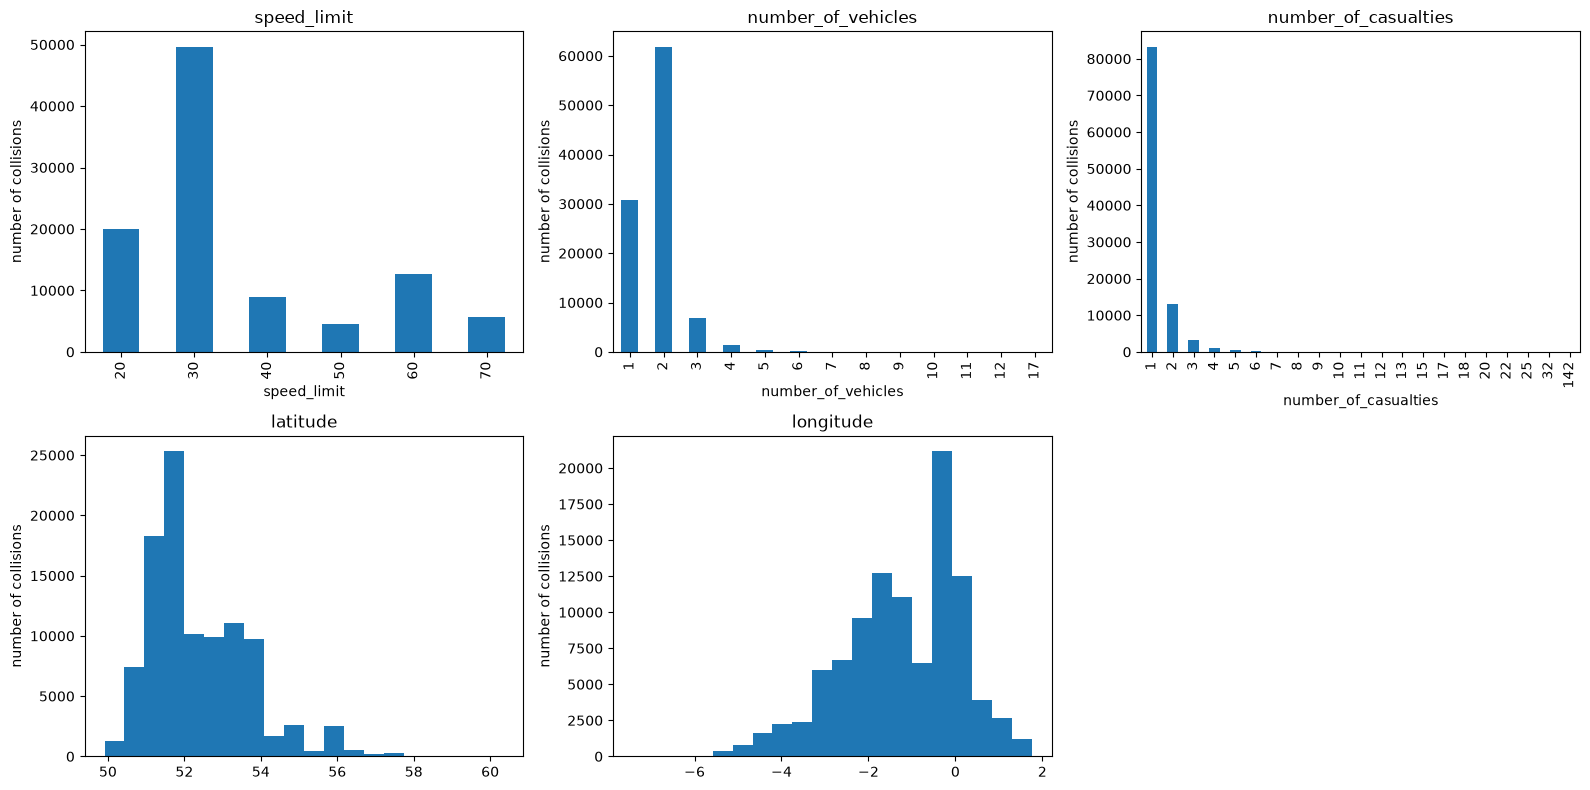

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

# frequency histograms
for ax, col in zip(axes[:3], ["speed_limit", "number_of_vehicles", "number_of_casualties"]):
    collision_df[col].value_counts().sort_index().plot(kind="bar", ax=ax, title=col)

# equi-width histograms
for ax, col in zip(axes[3:5], ["latitude", "longitude"]):
    collision_df[col].plot(kind="hist", bins=20, ax=ax, title=col)

axes[5].axis("off")   # sixth panel is empty

for ax in axes[:5]:
    ax.set_ylabel("number of collisions")

plt.tight_layout()
plt.show()

In the histograms presented above we can see the distributions of 5 numeric features.

- **speed_limit:** Most collisions are concentrated at 30mph, followed by 20mph, and then 60mph. 40, 50, and 70 mph have fewer collisions.
- **number_of_vehicles:** Most collisions involve 2 vehicles or 1 vehicle (almost half as many collisions as with 2 vehicles). Then the number of collisions falls sharply as the number of vehicles involved in the collision increases. The distribution is skewed to the right, with very few collisions involving many cars.
- **number_of_casualties:** Most collisions have exactly one casualty, and the number of collisions falls sharply again as the number of casualties increases. The distribution here is even more skewed with very few collisions having a high number of casualties. We can also spot an extreme value of 142 casualties in a single collision.
- **latitude:** Most collisions lie between 51 and 54 degrees north, with the biggest group concentrated between 51.5 and 52. After 54 degrees the number of collisions drop, and there is a light skewness reaching 60 degrees.
- **longitude:** Most collisions lie between -2 and 0, with the biggest group concentrated between -0.5 and 0. Before -2 and after 0 the number of collisions drop, and there is a light left skewness reaching -6.

In [37]:
# calculate the constancy of every column in the collisions df

most_freq_value = collision_df.apply(lambda col: col.value_counts().index[0]) # most frequent value in every column

constancy_df = collision_df.apply(lambda col: col.value_counts().iloc[0] / num_of_rows) # most frequent value count in every column divided by the total number of rows
constancy_df = constancy_df.reset_index() # reset index to make the column names as a column in the df
constancy_df.columns = ['Column Name', 'Constancy'] # rename the cols of this new df
constancy_df["Most Frequent Value"] = most_freq_value.values # add a new column with the most frequent value of every column
constancy_df.sort_values(by="Constancy", ascending=False, inplace=True) # sort the new df by the constancy column in descending order, so cols with highest constancy are on the top
constancy_df


,Column Name,Constancy,Most Frequent Value
1,collision_year,1.000000,2025
14,local_authority_district,1.000000,-1
35,carriageway_hazards,0.900025,0
38,trunk_road_flag,0.866486,2
22,junction_detail_historic,0.865511,-1
33,special_conditions_at_site,0.865383,-1
34,carriageway_hazards_historic,0.865324,-1
27,pedestrian_crossing_human_control_historic,0.865324,-1
28,pedestrian_crossing_physical_facilities_historic,0.865314,-1
41,collision_injury_based,0.865284,1


Constancy is the count of the most frequent value in every attribute divided by the total number of rows.

`collision_year` and `local_authority_district` hold the same exact value in all their records. `collision_year` has always the value 2025 since the dataset contains the road collisions for 2025. `local_authority_district` has always the value -1 which based on the data guide indicates a deprecated code. `carriageway_hazards` and `trunk_road_flag` have dominant values, 0 and 2 respectively, since their constancy is close to 1. So, from these attributes we can get that most collisions happen on non-trunk roads, and on roads with no hazards on the carriageway.

The 5 next attributes (from `junction_detail_historic` to `pedestrian_crossing_physical_facilities_historic`) share the same dominant value -1 which based on the data guide indicate missing data or out of range. So, most of their values are disguised missing values and these attributes are not useful.

Quartiles sort the values of a column and cut them into four groups which contain the same number of rows. These three cuts are Q1 (25% of the rows are at or below it), the median (50%), and Q3 (75%). Along with the minimum and maximum values of the attribute, they give a summary about where most values of this attribute lie and how they spread. They are computed on numeric features because there is no meaning in the order and distance between the labels.

In [38]:
quartiles_cols = ['speed_limit', 'number_of_vehicles', 'number_of_casualties', 'longitude', 'latitude'] # select the columns for which we want to calculate the quartiles

quartiles = collision_df[quartiles_cols].quantile([0, 0.25, 0.5, 0.75, 1]).T #calculate the quartiles of the selected columns
quartiles.columns = ['min', 'Q1', 'median', 'Q3', 'max'] # rename the cols of this new df
quartiles

,min,Q1,median,Q3,max
speed_limit,20.00000,30.00000,30.00000,40.00000,70.00000
number_of_vehicles,1.00000,1.00000,2.00000,2.00000,17.00000
number_of_casualties,1.00000,1.00000,1.00000,1.00000,142.00000
longitude,-7.41772,-2.11870,-1.13891,-0.13791,1.75559
latitude,49.91253,51.46446,51.88864,53.32586,60.34525


- **speed_limit:** Since Q1, median are equal to 30, at least half of the collisions happen at 30mph or lower.
- **number_of_vehicles:** Since Q1 is equal to 1 and median, Q3 are equal to 2, at least three quarters of the collisions have 2 or less vehicles involved. The maximum number 17 is one of the numbers causing the right skewness we saw in the histogram.
- **number_of_casualties:** Since Q1, median, Q3 are equal to 1, at least three quarters of the collisions have exactly one casualty. The maximum value 142 is the extreme value we also saw in the histogram.
- **longitude:** Since Q1 = -2.12, median = -1.14, and Q3 = -0.14, the middle half of the values lies between -2.12 and -0.14. The minimum value of -7.42 is much further from Q1 than the maximum value of 1.76 from Q3. So, the values below Q1 are more spread out which matches the light left skewness we saw on the histogram.
- **latitude:** Since min = 49.91, Q1 = 51.46, median = 51.89, and Q3 = 53.33, three quarters of the collisions happen between almost 50 and 53.3 degrees. Above the Q3 the values are more spread out which matches the right skewness we saw on the histogram.

Benford's law says that in many real-world numbers the first digit is not evenly distributed. The digit 1 comes first about 30% of the time, and each larger digit is less common. If a column looks different than that, it is possible that it had been made up.

So, we count how often each first digit appears in the `location_easting_osgr` and `location_northing_osgr` features, and we compare it with Benford percentages. We use these features as they are numbers with a wide range of values.

In [39]:
rows_benfords = []
for digit in range(1, 10):
    benfords = np.log10(1 + 1 / digit)
    rows_benfords.append({"Digit": digit, "Benford's Law Probability": benfords})
benfords_df = pd.DataFrame(rows_benfords)

for col in ['location_easting_osgr', 'location_northing_osgr']:
    first_digit = collision_df[col].dropna().astype(str).str[0].astype(int) # drop the nulls, convert to str, get the first char->first digit, convert the 1st digit back to int
    first_digit_counts_share = first_digit.value_counts(normalize=True) # count how many times each digit appears but as a share of all rows in the column
    
    benfords_df[col] = benfords_df["Digit"].map(first_digit_counts_share).fillna(0)

benfords_df.round(4)


,Digit,Benford's Law Probability,location_easting_osgr,location_northing_osgr
0,1,0.3010,0.0075,0.4168
1,2,0.1761,0.0555,0.1783
2,3,0.1249,0.2106,0.1702
3,4,0.0969,0.3166,0.1245
4,5,0.0792,0.3749,0.0422
5,6,0.0669,0.0350,0.0331
6,7,0.0580,0.0000,0.0093
7,8,0.0512,0.0000,0.0083
8,9,0.0458,0.0000,0.0174


- **location_easting_osgr:** it does not follow Benford's law at all. Most values start with 5 (37.49%), then with 4 (31.66%), then with 3 (21.06%), and then with 2 (5.55%). Digit 1 is almost never first (0.75%), and the digits 7, 8, and 9 never appear. The reason behind this is that this attribute is a position on the map so its values fall into a specific range. It is not a naturally growing number, so Benford's law is not expected to hold and does not indicate that it is a fake attribute.
- **location_northing_osgr:** it follows the general idea of Benford's law, since its most common first digit is 1 (41.68%), followed by 2 (17.83%), 3 (17.02%), 4 (12.45%), and larger digits appear more rarely. However, in `location_northing_osgr` some digits appear to be more common than expected from Benford's law (like 1 that appears 41.68% instead of 30.1%), and some other digits appear to be less common (like 5 that appears 4.22% instead of 7.92%). This attribute is also a position on the map, so the fact that it roughly follows the Benford's law is just a result of how collisions are spread in the country and not a sign of a natural increasing number.

## Step 2: Correlation Before Imputation

We use seven numeric features to calculate their correlation based on the previous statistics and the data guide so that we will not include categorical features (like `road_type`, `collision_year`) or features that overlap with one another (`location_easting_osgr` carries same information as `longitude`, `location_northing_osgr` carries same information as `latitude`). So, the seven features are `longitude`, `latitude`, `number_of_vehicles`, `number_of_casualties`, `speed_limit`, `first_road_number`, and `second_road_number`.

The Pearson correlation measures how strongly two features move together. There is a scale from -1 to +1. A positive value means that when one feature increases, the other tends to increase too, and the closer to +1 the stronger the relationship. A negative value means that when a feature increases, the other tends to decrease, and the closer to -1 the stronger the relationship. A value close to 0 means that there is no linear relationship.

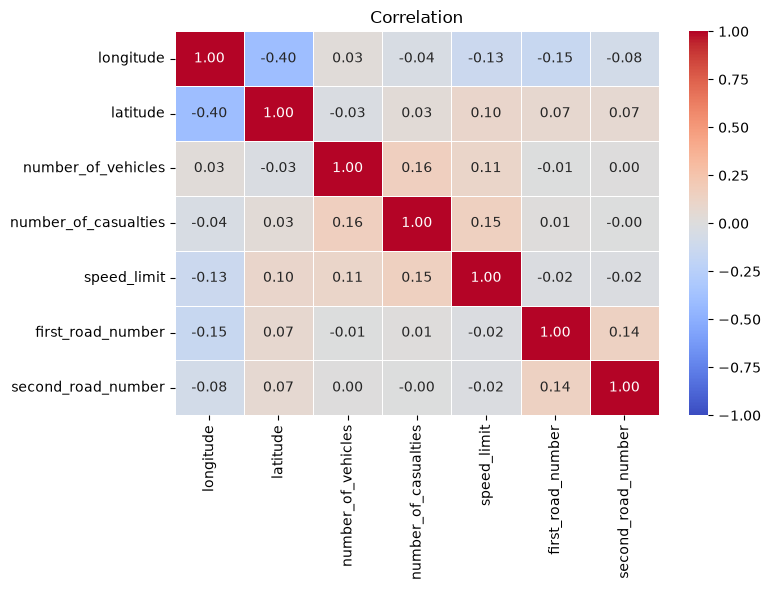

In [40]:
correlation_cols = ["longitude", "latitude", "number_of_vehicles", "number_of_casualties",
                    "speed_limit", "first_road_number", "second_road_number"]

# compute the correlation without removing missing values
correlation_matrix = collision_df[correlation_cols].corr(method="pearson")

plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation")
plt.tight_layout()
plt.show()

Most of the correlations are close to 0, so there is almost no linear relationship for the selected columns. The strongest correlation is spotted between `longitude` and `latitude` (-0.40) which is a moderate negative relationship. This correlation comes from the shape of Great Britain where places further north tend to be further west too. There is also a low positive correlation between `number_of_vehicles`, `number_of_casulaties`, and `speed_limit` (vehicles & speed limit -> 0.11, casualties & speed limit 0.15, and vehicles & casualties 0.16) which means that collisions in roads with higher speed limits tend to involve a few more vehicles and casualties, but the correlation is really low.

## Step 3: Removing Disguised Values and Replacing with NULLs

Based on the data guide there are some attributes in the dataset that have disguised missing values. Out of the seven features we used to compute the correlation, three of them are mentioned in the data guide to have the value -1 as an indicator for missing values. These three features are `speed_limit`, `first_road_number`, and `second_road_number`. `speed_limit` has also the value 99 indicating an unknown value.

In [41]:
disguise_missing_values_per_col = {
    "speed_limit": [-1, 99],
    "first_road_number": [-1],
    "second_road_number": [-1],
}

correlation_cols_df = collision_df[correlation_cols].copy()
for col, disguise_values in disguise_missing_values_per_col.items():
    for disguise_value in disguise_values:
        print(f"Column {col} contained {(correlation_cols_df[col] == disguise_value).sum()} disguised missing values of {disguise_value}.")
        correlation_cols_df[col] = correlation_cols_df[col].replace(disguise_value, np.nan)
print(f"Nulls in correlation columns selected before replacement: {collision_df[correlation_cols].isna().sum().sum()}")
print(f"Nulls in correlation columns selected after replacement: {correlation_cols_df[correlation_cols].isna().sum().sum()}")

Column speed_limit contained 0 disguised missing values of -1.
Column speed_limit contained 0 disguised missing values of 99.
Column first_road_number contained 6 disguised missing values of -1.
Column second_road_number contained 25105 disguised missing values of -1.
Nulls in correlation columns selected before replacement: 4
Nulls in correlation columns selected after replacement: 25115


## Step 4: Imputation of Missing Values

We will fill every null value, in the seven features selected to compute their correlation, with the median of its column. we chose the median because it is simple and it is not affected by possible extreme values as the mean does.

In [42]:
medians = correlation_cols_df.median() # compute the median of each column (nulls are ignored)

imputed_correlation_cols_df = correlation_cols_df.fillna(medians) # replace the nulls with the median of each column

print(f"Nulls in correlation columns selected after the imputation: {imputed_correlation_cols_df.isna().sum().sum()}")

Nulls in correlation columns selected after the imputation: 0


## Step 5: Correlation After Imputation

We compute again the Pearson correlation between the seven features selected before (3), but this time the data of the seven selected features contain no missing data or disguise missing data. Their missing data and disguise missing data have been imputed.

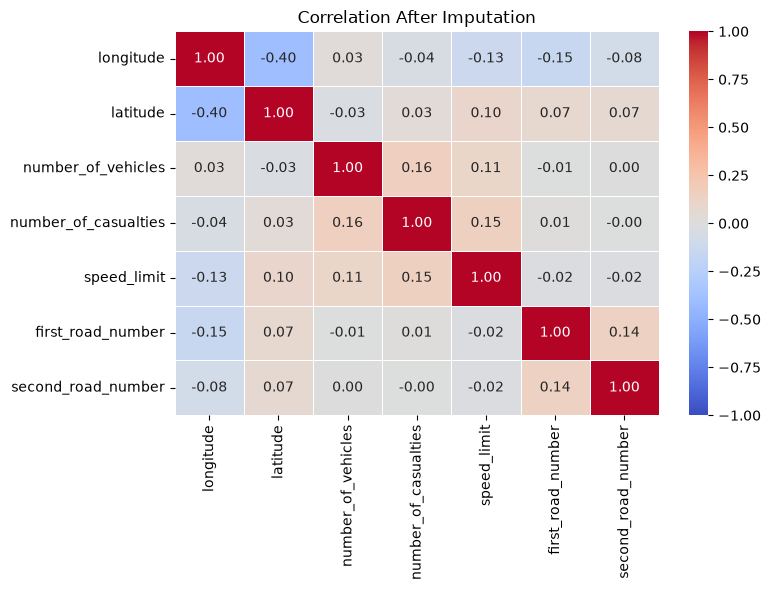

In [43]:
# compute the correlation on the imputed data
correlation_matrix_imputed = imputed_correlation_cols_df.corr(method="pearson")

plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix_imputed, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation After Imputation")
plt.tight_layout()
plt.show()

In [44]:
diff = correlation_matrix_imputed - correlation_matrix
diff

,longitude,latitude,number_of_vehicles,number_of_casualties,speed_limit,first_road_number,second_road_number
longitude,0.000000e+00,1.053645e-07,3.150294e-07,-3.512846e-07,1.867514e-07,-1.951380e-06,-0.000025
latitude,1.053645e-07,0.000000e+00,-1.940841e-06,2.250276e-06,6.652928e-06,2.765647e-06,-0.000019
number_of_vehicles,3.150294e-07,-1.940841e-06,0.000000e+00,0.000000e+00,0.000000e+00,-2.460906e-07,-0.000002
number_of_casualties,-3.512846e-07,2.250276e-06,0.000000e+00,0.000000e+00,0.000000e+00,1.095236e-07,0.000016
speed_limit,1.867514e-07,6.652928e-06,0.000000e+00,0.000000e+00,0.000000e+00,-3.324695e-07,0.000111
first_road_number,-1.951380e-06,2.765647e-06,-2.460906e-07,1.095236e-07,-3.324695e-07,0.000000e+00,-0.000009
second_road_number,-2.502921e-05,-1.922264e-05,-2.489318e-06,1.554525e-05,1.108972e-04,-8.540104e-06,0.000000


## Step 6: Comparison Between Correlations Before and After the Imputation

The correlation matrices before and after the imputation are practically identical. From the printed matrix above we can see that the differences between any two values are really low (below 0.001).

This happens because the only attribute with many null values is `second_road_number` (25,105), in which -1 was replaced with the median 0, a value really close to -1 compared with the size of the road numbers which go up to 9,999. The other attributes (that contained missing values) changed in only a small number of rows (6 for `first_road_number`, 2 in `latitude`, and 2 in `longitude`). Moreover, median is an imputation method that inserts one single value in every missing value, so it does not take into account relationships between the different attributes. 

So, all these led to get the same correlations between the seven selected features even after the imputation of missing values. The disguise missing values did not distort the correlations between the seven selected features, and by imputing them did not change anything. Thus, the main findings regarding the correlations stay the same.